# Aircraft Engine Predictive Maintenance: Modeling and Evaluation
**BDA 696 · Airline Anomalies** · NASA C-MAPSS FD001-FD004

This notebook continues after the three preprocessing scripts in `scripts/`:

| Step | Done by | Output |
|---|---|---|
| `1_clean_cmapss.py` | script | `data/cleaned/` |
| `2_create_rul_labels.py` | script | `data/labeled/` (RUL for every training row) |
| `3_feature_engineer.py` | script | `data/engineered/` (80/20 engine split, 30-cycle history features, feature report) |
| **This notebook** | | EDA, baselines, Random Forest, XGBoost, OPTIONAL Ridge / MLP / LSTM, nested CV, final test, metrics, figures, maintenance-priority view |

**Run the three scripts first**, then run this notebook from top to bottom.

**Main rules followed here (from the project outline)**
* Every subset (FD001-FD004) is its own experiment with its own models.
* All splits are made by **whole engine**, never by row, so one engine is never on both sides.
* Main target is the **uncapped** RUL. The 130-cycle cap is only an OPTIONAL extension, always scored on the true uncapped labels.
* Model choice uses **nested grouped cross-validation** for the core models (5 outer x 3 inner folds).
* The **official test set is used once**, at the end, after all choices are frozen.
* Sections marked **OPTIONAL** can be switched off in the settings cell.

## 0. Settings
Change only this cell. `QUICK_RUN = True` runs FD001 with tiny searches so you can check that everything works in a few minutes.
The full run (all four subsets) takes several hours on a normal laptop, mostly the Random Forest searches on FD002 / FD004.

In [ ]:
# ---- Run switches ----
QUICK_RUN = False               # True = FD001 only + tiny searches (to test the notebook quickly)
RUN_OPTIONAL_MODELS = True       # OPTIONAL models: Ridge, MLP, LSTM
RUN_OPTIONAL_EXTENSION = True    # OPTIONAL extension: RUL cap 130 + per-condition normalization
SAVE_RF_MODELS = False           # Random Forest files can be hundreds of MB each

# ---- Fixed settings from the project outline ----
SUBSETS = ["FD001"] if QUICK_RUN else ["FD001", "FD002", "FD003", "FD004"]
RANDOM_STATE = 42
SEEDS = [42] if QUICK_RUN else [42, 43, 44]   # repeat RF, XGBoost and LSTM with 3 seeds
HISTORY_WINDOW = 30            # cycles of history (same as script 3)
N_ENDPOINTS = 5                # endpoints per held-out engine
OUTER_FOLDS = 3 if QUICK_RUN else 5
INNER_FOLDS = 3
NEAR_FAILURE_RUL = 30          # "near failure" = true RUL <= 30 (study threshold)
OVERESTIMATE_LIMIT = 10        # dangerous error = predicted RUL more than 10 cycles too high
FEW_CASES = 20                 # warn when fewer near-failure test engines than this
N_BOOTSTRAP = 1000
RUL_CAP = 130                  # OPTIONAL extension only
N_CONDITIONS = {"FD001": 1, "FD002": 6, "FD003": 1, "FD004": 6}   # from the NASA documentation

# Random-search budget (number of settings tried from each search space)
N_ITER = {"random_forest": 10, "xgboost": 20, "ridge": 6, "mlp": 6}
LSTM_TRIALS, LSTM_MAX_EPOCHS, LSTM_PATIENCE, LSTM_BATCH = 4, 40, 5, 256
if QUICK_RUN:
    N_ITER = {name: 2 for name in N_ITER}
    LSTM_TRIALS, LSTM_MAX_EPOCHS = 1, 3

In [ ]:
import json
import os
import pickle
import platform
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.cluster import KMeans
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GroupKFold, ParameterSampler, RandomizedSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import xgboost
from xgboost import XGBRegressor

NOTEBOOK_START = time.time()
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 2)
pd.set_option("display.max_columns", 40)

# Folders (works if the notebook is in the project root or in notebooks/)
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
ENGINEERED_DIR = PROJECT_ROOT / "data" / "engineered"
RESULTS_DIR = PROJECT_ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
TABLE_DIR = RESULTS_DIR / "tables"
PRED_DIR = RESULTS_DIR / "predictions"
MODEL_DIR = RESULTS_DIR / "models"
CONFIG_DIR = RESULTS_DIR / "configs"
for folder in [FIG_DIR, TABLE_DIR, PRED_DIR, MODEL_DIR, CONFIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Plot style: one color per entity, used the same way in every figure
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6")
FEATURE_SET_COLORS = {"current": BLUE, "history": ORANGE, "sequence": AQUA, "none": "#8a8984"}
MODEL_ORDER = ["median", "linear", "random_forest", "xgboost", "ridge", "mlp", "lstm"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e4e3df", "axes.titlelocation": "left",
                     "axes.titleweight": "bold", "legend.frameon": False})


def save_figure(fig, name):
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    plt.show()


# Record software and hardware for the reproducibility appendix
versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
            "matplotlib": plt.matplotlib.__version__, "seaborn": sns.__version__}
hardware = {"platform": platform.platform(), "processor": platform.processor(), "cpu_count": os.cpu_count()}
print("Project root:", PROJECT_ROOT)
print(versions)
print(hardware)

Project root: /tmp/claude-0/-home-user/55e1d562-51e0-5b6d-9458-d82f4f871ad5/scratchpad/repo/AircraftMaintenance
{'python': '3.13.18', 'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}
{'platform': 'Linux-6.18.44-fc-v726-x86_64-with-glibc2.39', 'processor': 'x86_64', 'cpu_count': 4}


## 1. Load the engineered data
Reads the files written by `3_feature_engineer.py`. The feature report says which sensors were kept
(near-constant sensors were removed using development engines only).

Two feature sets are compared for every tabular model:
* **current** = observed age (`cycle`) + 3 operating settings + kept sensors at this cycle
* **history** = current + 30-cycle rolling mean, rolling std and one-cycle change of each kept sensor (past only)

In [ ]:
OP_SETTING_COLS = ["op_setting_1", "op_setting_2", "op_setting_3"]


def load_subset(subset):
    # Read engineered train/test files and the feature report for one subset
    paths = {
        "train": ENGINEERED_DIR / f"engineered_train_{subset}.csv",
        "test": ENGINEERED_DIR / f"engineered_test_{subset}.csv",
        "report": ENGINEERED_DIR / f"feature_report_{subset}.csv",
    }
    for path in paths.values():
        if not path.exists():
            raise FileNotFoundError(f"{path} not found. Run scripts 1, 2 and 3 in scripts/ first.")

    train = pd.read_csv(paths["train"]).sort_values(["engine_key", "cycle"]).reset_index(drop=True)
    test = pd.read_csv(paths["test"]).sort_values(["engine_key", "cycle"]).reset_index(drop=True)
    report = pd.read_csv(paths["report"])

    selected = report[report["selected"]]
    sensors = selected.loc[selected["feature_group"] == "current_sensor", "feature"].tolist()
    features = {"current": ["cycle"] + OP_SETTING_COLS + sensors,
                "history": selected["feature"].tolist()}
    return {"train": train, "test": test, "sensors": sensors, "features": features}


data, prep_seconds = {}, {}
for subset in SUBSETS:
    start = time.time()
    data[subset] = load_subset(subset)
    prep_seconds[subset] = time.time() - start
    d = data[subset]
    print(f"{subset}: train {d['train'].shape}, test {d['test'].shape}, "
          f"{len(d['sensors'])} sensors kept, {len(d['features']['history'])} history features")

FD001: train (20631, 76), test (13096, 76), 15 sensors kept, 64 history features


FD002: train (53759, 94), test (33991, 94), 21 sensors kept, 88 history features


FD003: train (24720, 79), test (16596, 79), 16 sensors kept, 68 history features


FD004: train (61249, 94), test (41214, 94), 21 sensors kept, 88 history features


## 2. Exploratory data analysis
Following the outline, exploratory decisions use **development engines only** (validation and test engines are not looked at).
For FD002 / FD004 the sensors depend strongly on the flight condition, so sensor plots use values
**standardized within each operating condition** (conditions found with KMeans on the three settings).

In [ ]:
def fit_condition_normalizer(fit_df, sensors, n_conditions):
    # Learn condition groups (KMeans on the 3 settings) and sensor mean/std inside each group
    kmeans = KMeans(n_clusters=n_conditions, n_init=10, random_state=RANDOM_STATE).fit(fit_df[OP_SETTING_COLS])
    condition = kmeans.labels_
    means = fit_df[sensors].groupby(condition).mean()
    stds = fit_df[sensors].groupby(condition).std().replace(0, 1).fillna(1)
    return kmeans, means, stds


def apply_condition_normalizer(df, sensors, normalizer):
    # Replace each sensor by its z-score inside the row's operating condition
    kmeans, means, stds = normalizer
    condition = kmeans.predict(df[OP_SETTING_COLS])
    out = df.copy()
    out[sensors] = (df[sensors].to_numpy() - means.loc[condition].to_numpy()) / stds.loc[condition].to_numpy()
    return out


dev_data, dev_normalized = {}, {}
for subset in SUBSETS:
    train = data[subset]["train"]
    dev = train[train["split"] == "development"]
    normalizer = fit_condition_normalizer(dev, data[subset]["sensors"], N_CONDITIONS[subset])
    dev_data[subset] = dev
    dev_normalized[subset] = apply_condition_normalizer(dev, data[subset]["sensors"], normalizer)

# 2.1 Profile table
profile_rows = []
for subset in SUBSETS:
    train, test = data[subset]["train"], data[subset]["test"]
    life = train.groupby("engine_key")["cycle"].max()
    test_length = test.groupby("engine_key")["cycle"].max()
    profile_rows.append({
        "subset": subset, "train_rows": len(train), "test_rows": len(test),
        "train_engines": train["engine_key"].nunique(), "test_engines": test["engine_key"].nunique(),
        "development_engines": train.loc[train["split"] == "development", "engine_key"].nunique(),
        "validation_engines": train.loc[train["split"] == "validation", "engine_key"].nunique(),
        "sensors_kept": len(data[subset]["sensors"]),
        "history_features": len(data[subset]["features"]["history"]),
        "missing_values": int(train.isna().sum().sum() + test.isna().sum().sum()),
        "life_min": life.min(), "life_median": life.median(), "life_max": life.max(),
        "shortest_test_history": test_length.min(),
        "test_engines_shorter_than_window": int((test_length < HISTORY_WINDOW).sum()),
    })
profile = pd.DataFrame(profile_rows)
profile.to_csv(TABLE_DIR / "data_profile.csv", index=False)
display(profile)

,subset,train_rows,test_rows,train_engines,test_engines,development_engines,validation_engines,sensors_kept,history_features,missing_values,life_min,life_median,life_max,shortest_test_history,test_engines_shorter_than_window
0,FD001,20631,13096,100,100,80,20,15,64,0,128,199.0,362,31,0
1,FD002,53759,33991,260,259,208,52,21,88,0,128,199.0,378,21,6
2,FD003,24720,16596,100,100,80,20,16,68,0,145,220.5,525,38,0
3,FD004,61249,41214,249,248,199,50,21,88,0,128,234.0,543,19,11


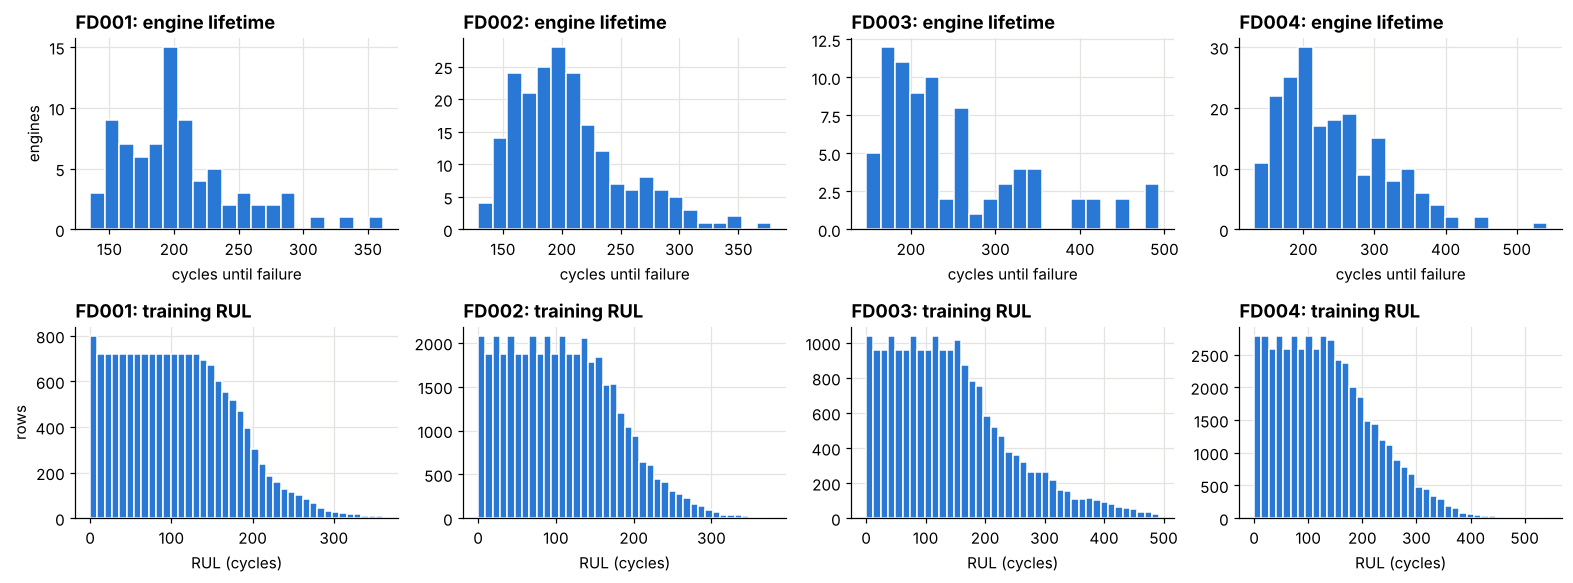

Engines live very different lengths, so RUL cannot be read from the cycle number alone.
The RUL distribution is skewed: many rows have large RUL (early life), few have RUL near 0.


In [ ]:
# 2.2 Engine lifetimes and RUL distribution (development engines)
fig, axes = plt.subplots(2, len(SUBSETS), figsize=(3.6 * len(SUBSETS), 5.4), squeeze=False)
for i, subset in enumerate(SUBSETS):
    dev = dev_data[subset]
    axes[0, i].hist(dev.groupby("engine_key")["cycle"].max(), bins=20, color=BLUE, edgecolor="white")
    axes[0, i].set_title(f"{subset}: engine lifetime")
    axes[0, i].set_xlabel("cycles until failure")
    axes[1, i].hist(dev["RUL"], bins=40, color=BLUE, edgecolor="white")
    axes[1, i].set_title(f"{subset}: training RUL")
    axes[1, i].set_xlabel("RUL (cycles)")
axes[0, 0].set_ylabel("engines")
axes[1, 0].set_ylabel("rows")
fig.tight_layout()
save_figure(fig, "eda_lifetimes_rul.png")
print("Engines live very different lengths, so RUL cannot be read from the cycle number alone.")
print("The RUL distribution is skewed: many rows have large RUL (early life), few have RUL near 0.")

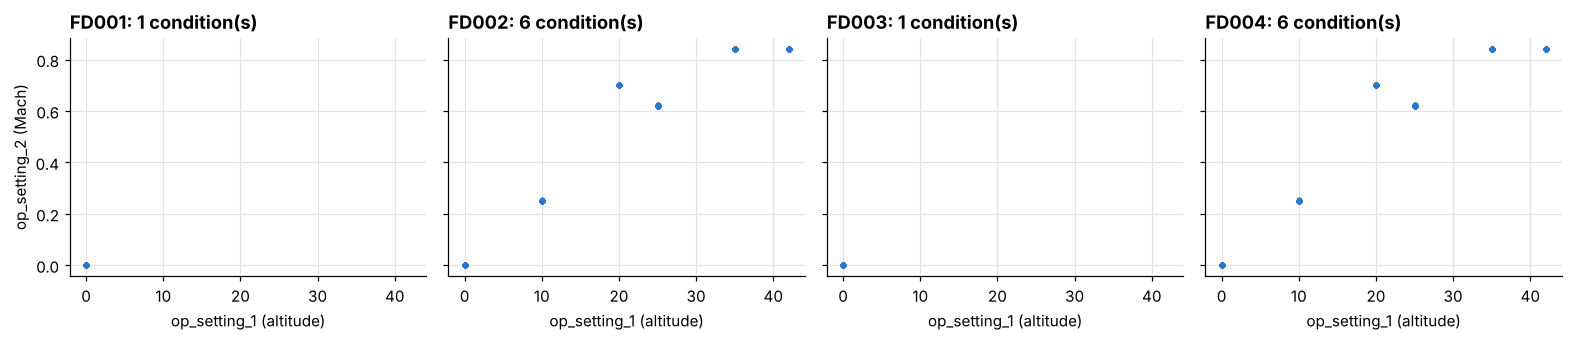

In [ ]:
# 2.3 Operating settings: one condition (FD001/FD003) vs six conditions (FD002/FD004)
fig, axes = plt.subplots(1, len(SUBSETS), figsize=(3.6 * len(SUBSETS), 3.2), squeeze=False, sharex=True, sharey=True)
for i, subset in enumerate(SUBSETS):
    sample = dev_data[subset].sample(min(3000, len(dev_data[subset])), random_state=RANDOM_STATE)
    axes[0, i].scatter(sample["op_setting_1"], sample["op_setting_2"], s=6, alpha=0.4, color=BLUE)
    axes[0, i].set_title(f"{subset}: {N_CONDITIONS[subset]} condition(s)")
    axes[0, i].set_xlabel("op_setting_1 (altitude)")
axes[0, 0].set_ylabel("op_setting_2 (Mach)")
fig.tight_layout()
save_figure(fig, "eda_operating_settings.png")

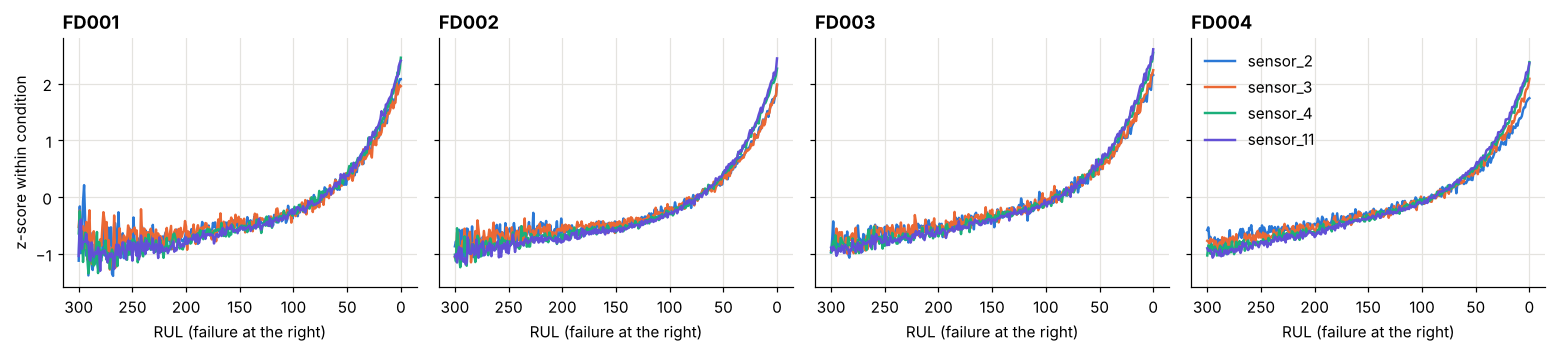

Sensors stay almost flat while RUL is large and change quickly in the last ~100 cycles.


In [ ]:
# 2.4 Sensor degradation: average (condition-standardized) value at each RUL
TREND_SENSORS = ["sensor_2", "sensor_3", "sensor_4", "sensor_11"]
TREND_COLORS = [BLUE, ORANGE, AQUA, VIOLET]
fig, axes = plt.subplots(1, len(SUBSETS), figsize=(3.6 * len(SUBSETS), 3.3), squeeze=False, sharey=True)
for i, subset in enumerate(SUBSETS):
    normalized = dev_normalized[subset]
    average = normalized[normalized["RUL"] <= 300].groupby("RUL")[TREND_SENSORS].mean()
    for sensor, color in zip(TREND_SENSORS, TREND_COLORS):
        axes[0, i].plot(average.index, average[sensor], color=color, lw=1.6, label=sensor)
    axes[0, i].invert_xaxis()
    axes[0, i].set_title(subset)
    axes[0, i].set_xlabel("RUL (failure at the right)")
axes[0, 0].set_ylabel("z-score within condition")
axes[0, -1].legend(loc="upper left")
fig.tight_layout()
save_figure(fig, "eda_sensor_trends.png")
print("Sensors stay almost flat while RUL is large and change quickly in the last ~100 cycles.")

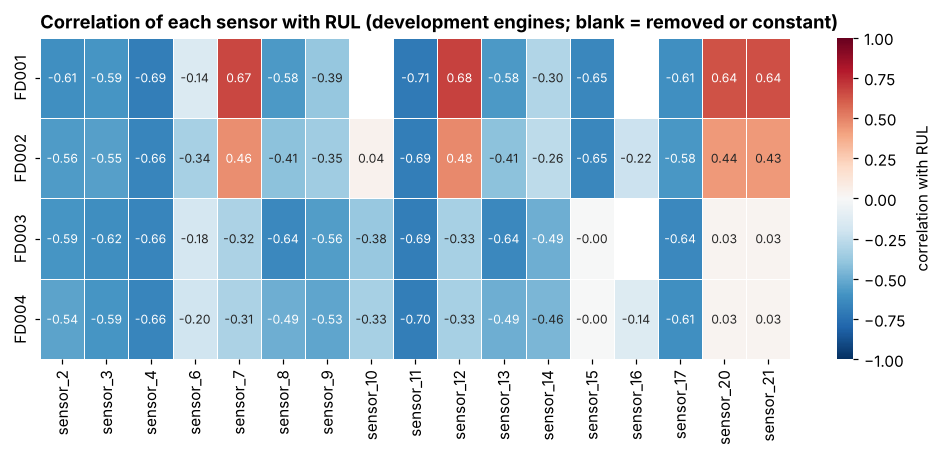

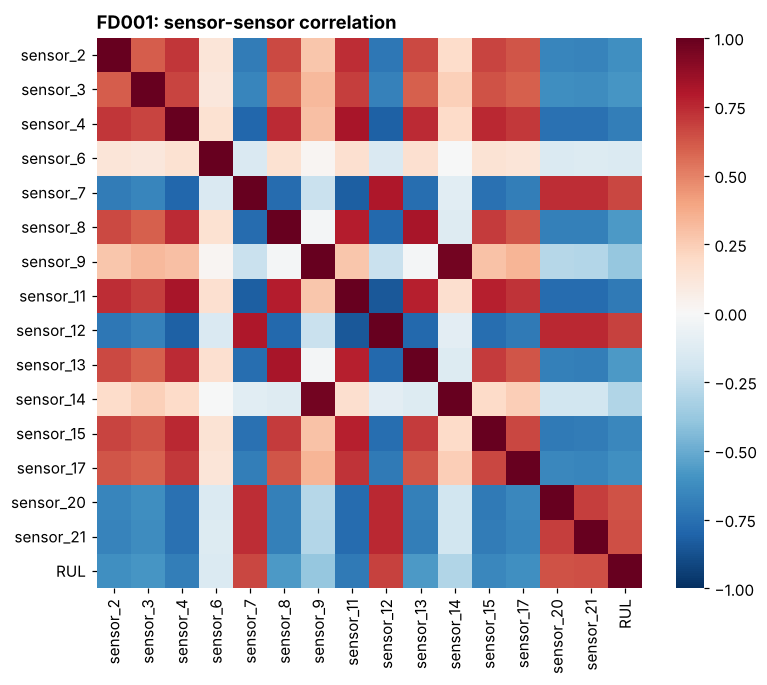

Many sensors are strongly correlated with each other (they all react to the same wear).


In [ ]:
# 2.5 Correlation of each sensor with RUL (condition-standardized), and sensor-sensor correlation for the first subset
corr_rows = {}
for subset in SUBSETS:
    normalized = dev_normalized[subset]
    # skip sensors that are constant after condition normalization (their correlation is undefined)
    varying = [s for s in data[subset]["sensors"] if normalized[s].std() > 1e-8]
    corr_rows[subset] = normalized[varying].corrwith(normalized["RUL"])
corr_with_rul = pd.DataFrame(corr_rows).T
corr_with_rul = corr_with_rul[[f"sensor_{i}" for i in range(1, 22) if f"sensor_{i}" in corr_with_rul.columns]]

fig, ax = plt.subplots(figsize=(11, 0.6 * len(SUBSETS) + 1.4))
sns.heatmap(corr_with_rul, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=0.5, linecolor="white", cbar_kws={"label": "correlation with RUL"}, ax=ax)
ax.grid(False)
ax.set_title("Correlation of each sensor with RUL (development engines; blank = removed or constant)")
save_figure(fig, "eda_correlation_with_rul.png")

first = SUBSETS[0]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(dev_normalized[first][data[first]["sensors"] + ["RUL"]].corr(), cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.grid(False)
ax.set_title(f"{first}: sensor-sensor correlation")
save_figure(fig, "eda_sensor_correlation.png")
print("Many sensors are strongly correlated with each other (they all react to the same wear).")

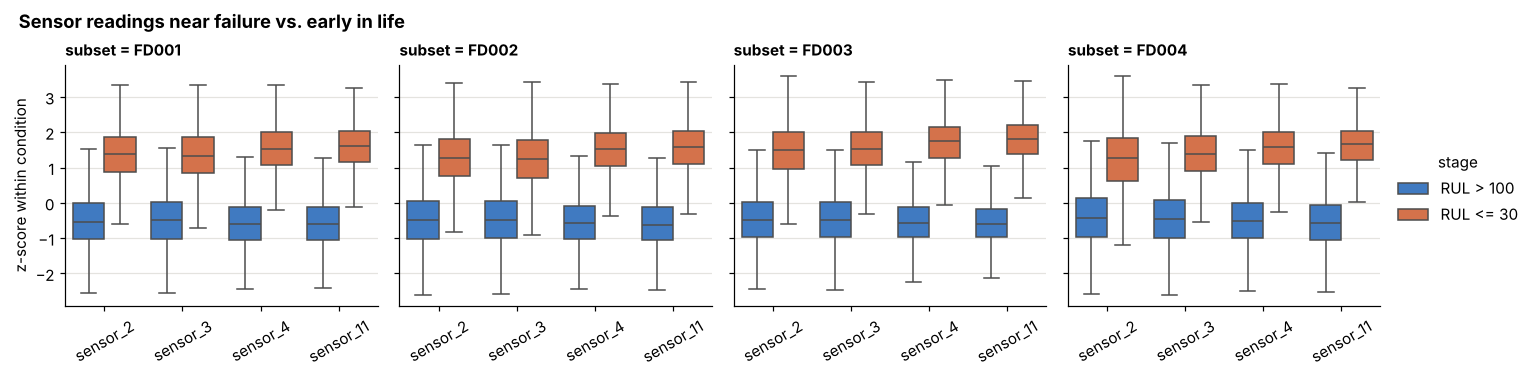

In [ ]:
# 2.6 Readings close to failure vs. early readings (accounting for operating condition)
#Z-score shows that when RUL <= 30 sensors shows data which are far from sample mean.
rows = []
for subset in SUBSETS:
    normalized = dev_normalized[subset]
    stage = np.where(normalized["RUL"] <= NEAR_FAILURE_RUL, f"RUL <= {NEAR_FAILURE_RUL}",
                     np.where(normalized["RUL"] > 100, "RUL > 100", "middle"))
    part = normalized.assign(stage=stage)
    part = part[part["stage"] != "middle"]
    long_format = part.melt(id_vars=["stage"], value_vars=TREND_SENSORS, var_name="sensor", value_name="z")
    long_format["subset"] = subset
    rows.append(long_format)
stage_df = pd.concat(rows)

grid = sns.catplot(data=stage_df, x="sensor", y="z", hue="stage", col="subset", kind="box", showfliers=False,
                   palette={f"RUL <= {NEAR_FAILURE_RUL}": ORANGE, "RUL > 100": BLUE}, height=3.2, aspect=1.0)
grid.set_axis_labels("", "z-score within condition")
grid.set_xticklabels(rotation=30)
grid.fig.suptitle("Sensor readings near failure vs. early in life", y=1.04, x=0.02, ha="left", fontweight="bold")
grid.savefig(FIG_DIR / "eda_near_failure_vs_early.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Endpoints, folds and metrics

**Endpoints** copy the test situation: we pick a cycle of a held-out engine (never the failure cycle, RUL > 0),
pretend the engine stopped there, and predict its RUL using only that cycle and earlier ones.
All history features are past-only, so the row at an endpoint contains no future information.
Each held-out engine gives **5 endpoints**, so every engine has the same weight.

**Outer folds** for nested CV: all training engines are shuffled (seed 42) and cut into 5 groups.

**Metrics**: MAE (main) and RMSE in cycles; near-failure MAE, count and % of predictions that are more than
10 cycles too high, for true RUL <= 30; engine-level bootstrap 95% intervals for test MAE and RMSE.

In [ ]:
def pick_endpoints(df, engine_keys, n_per_engine, seed):
    # Return row labels of n random cycles with RUL > 0 for every engine in engine_keys
    rng = np.random.default_rng(seed)
    chosen = []
    for key in sorted(engine_keys):
        rows = df.index[(df["engine_key"] == key) & (df["RUL"] > 0)].to_numpy()
        chosen.extend(rng.choice(rows, size=min(n_per_engine, len(rows)), replace=False))
    return np.array(sorted(chosen))


def make_outer_folds(engine_keys, n_folds, seed):
    # Shuffle whole engines and cut them into n_folds groups
    rng = np.random.default_rng(seed)
    shuffled = rng.permutation(sorted(engine_keys))
    return [sorted(fold.tolist()) for fold in np.array_split(shuffled, n_folds)]


def score(y_true, y_pred):
    # MAE, RMSE and near-failure metrics (errors in cycles; error = predicted - true)
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    error = y_pred - y_true
    near = y_true <= NEAR_FAILURE_RUL
    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "near_failure_n": int(near.sum()),
        "near_failure_MAE": np.mean(np.abs(error[near])) if near.any() else np.nan,
        "near_failure_over10_pct": 100 * np.mean(error[near] > OVERESTIMATE_LIMIT) if near.any() else np.nan,
    }


def bootstrap_ci(y_true, y_pred, n_boot=N_BOOTSTRAP, seed=RANDOM_STATE):
    # 95% interval for MAE and RMSE by resampling engines (one row per engine)
    error = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    rng = np.random.default_rng(seed)
    samples = error[rng.integers(0, len(error), size=(n_boot, len(error)))]
    maes = np.abs(samples).mean(axis=1)
    rmses = np.sqrt((samples ** 2).mean(axis=1))
    return {"MAE_CI_low": np.percentile(maes, 2.5), "MAE_CI_high": np.percentile(maes, 97.5),
            "RMSE_CI_low": np.percentile(rmses, 2.5), "RMSE_CI_high": np.percentile(rmses, 97.5)}


# Validation endpoints on the script-3 validation engines (used by the OPTIONAL models and the extension)
validation_endpoints, endpoint_tables = {}, []
for subset in SUBSETS:
    train = data[subset]["train"]
    validation_keys = train.loc[train["split"] == "validation", "engine_key"].unique()
    validation_endpoints[subset] = pick_endpoints(train, validation_keys, N_ENDPOINTS, RANDOM_STATE)
    endpoint_tables.append(train.loc[validation_endpoints[subset], ["subset", "engine_key", "cycle", "RUL"]])
    print(f"{subset}: {len(validation_endpoints[subset])} validation endpoints from {len(validation_keys)} engines")
pd.concat(endpoint_tables).to_csv(CONFIG_DIR / "validation_endpoints.csv", index=False)

FD001: 100 validation endpoints from 20 engines
FD002: 260 validation endpoints from 52 engines
FD003: 100 validation endpoints from 20 engines


FD004: 250 validation endpoints from 50 engines


## 4. Models and search spaces
| Model | Status | Notes |
|---|---|---|
| Median RUL | core baseline | predicts the median training RUL for every row |
| Linear regression | core baseline | standardized inputs |
| Random Forest | core | `max_samples=0.5`: each tree sees a random half of the rows (much faster on FD002/FD004) |
| XGBoost | core | histogram method |
| Ridge | **OPTIONAL** | regularized linear model |
| MLP | **OPTIONAL** | small sklearn neural network on the history features |
| LSTM | **OPTIONAL** | TensorFlow/Keras, raw 30-cycle windows (section 6) |

Hyperparameters are chosen by a **random search** over the spaces below (`N_ITER` settings each), scored by MAE with
3-fold `GroupKFold` (whole engines per fold). All predictions are clipped at 0, because RUL cannot be negative.

In [ ]:
SEARCH_SPACES = {
    "median": {},
    "linear": {},
    "random_forest": {"n_estimators": [100, 200],
                      "max_depth": [10, 15, 20, None],
                      "min_samples_leaf": [1, 5, 10, 20],
                      "max_features": [0.2, 0.33, 0.5, "sqrt"]},
    "xgboost": {"n_estimators": [200, 400, 800],
                "max_depth": [3, 4, 6, 8],
                "learning_rate": [0.02, 0.05, 0.1],
                "subsample": [0.7, 0.85, 1.0],
                "colsample_bytree": [0.5, 0.7, 1.0],
                "min_child_weight": [1, 5, 10]},
    "ridge": {"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    "mlp": {"mlpregressor__hidden_layer_sizes": [(64,), (128,), (64, 32), (128, 64)],
            "mlpregressor__alpha": [1e-4, 1e-3, 1e-2],
            "mlpregressor__learning_rate_init": [1e-3, 3e-3]},
}


def make_model(name, seed=RANDOM_STATE):
    # Create an untrained model with default settings
    if name == "median":
        return DummyRegressor(strategy="median")
    if name == "linear":
        return make_pipeline(StandardScaler(), LinearRegression())
    if name == "random_forest":
        return RandomForestRegressor(max_samples=0.5, n_jobs=-1, random_state=seed)
    if name == "xgboost":
        return XGBRegressor(tree_method="hist", n_jobs=-1, random_state=seed)
    if name == "ridge":
        return make_pipeline(StandardScaler(), Ridge())
    if name == "mlp":
        return make_pipeline(StandardScaler(), MLPRegressor(max_iter=200, early_stopping=True, random_state=seed))
    raise ValueError(name)


def tune(name, X, y, groups, refit=True):
    # Choose hyperparameters with grouped CV (whole engines per fold); return (model, best_params)
    space = SEARCH_SPACES[name]
    if not space:  # median and linear have nothing to tune
        return make_model(name).fit(X, y), {}
    n_combinations = int(np.prod([len(values) for values in space.values()]))
    search = RandomizedSearchCV(make_model(name), space, n_iter=min(N_ITER[name], n_combinations),
                                cv=GroupKFold(n_splits=INNER_FOLDS), scoring="neg_mean_absolute_error",
                                random_state=RANDOM_STATE, n_jobs=1, refit=refit)
    search.fit(X, y, groups=groups)
    return (search.best_estimator_ if refit else None), search.best_params_


def predict_rul(model, X):
    return np.clip(model.predict(X), 0, None)


CORE_RUNS = [("median", "none"),
             ("linear", "current"), ("linear", "history"),
             ("random_forest", "current"), ("random_forest", "history"),
             ("xgboost", "current"), ("xgboost", "history")]


def columns_for(subset, feature_set):
    # The median baseline ignores inputs, so any column works for it
    return data[subset]["features"]["current" if feature_set == "none" else feature_set]

## 5. Nested grouped cross-validation (core models)
For every subset: the training engines are split into 5 outer groups. In each outer round
1. the other 4 groups are used to **tune** the model with 3-fold grouped CV and refit it,
2. the held-out group (never seen during tuning) is scored at **5 endpoints per engine**.

Every engine is the unseen check exactly once, so each model gets **5 scores** (mean +/- spread) instead of one
possibly lucky validation score. Current and history feature sets are tuned separately.

In [ ]:
nested_rows, nested_params, outer_endpoint_tables, outer_fold_lists = [], [], [], {}
nested_start = time.time()

for subset in SUBSETS:
    train = data[subset]["train"]
    folds = make_outer_folds(train["engine_key"].unique(), OUTER_FOLDS, RANDOM_STATE)
    outer_fold_lists[subset] = folds

    for k, held_out in enumerate(folds):
        is_held_out = train["engine_key"].isin(held_out)
        fit_rows = train[~is_held_out]
        endpoint_rows = train.loc[pick_endpoints(train, held_out, N_ENDPOINTS, RANDOM_STATE + k)]
        outer_endpoint_tables.append(endpoint_rows[["subset", "engine_key", "cycle", "RUL"]].assign(outer_fold=k + 1))

        for name, feature_set in CORE_RUNS:
            cols = columns_for(subset, feature_set)
            start = time.time()
            model, params = tune(name, fit_rows[cols], fit_rows["RUL"], fit_rows["engine_key"])
            prediction = predict_rul(model, endpoint_rows[cols])
            nested_rows.append({"subset": subset, "outer_fold": k + 1, "model": name, "feature_set": feature_set,
                                **score(endpoint_rows["RUL"], prediction), "seconds": time.time() - start})
            nested_params.append({"subset": subset, "outer_fold": k + 1, "model": name,
                                  "feature_set": feature_set, "params": params})
        print(f"{subset} outer fold {k + 1}/{len(folds)} done  ({(time.time() - nested_start) / 60:.1f} min total)")

nested_results = pd.DataFrame(nested_rows)
nested_results.to_csv(TABLE_DIR / "nested_cv_by_fold.csv", index=False)
pd.concat(outer_endpoint_tables).to_csv(CONFIG_DIR / "outer_fold_endpoints.csv", index=False)

FD001 outer fold 1/5 done  (2.7 min total)


FD001 outer fold 2/5 done  (5.4 min total)


FD001 outer fold 3/5 done  (8.0 min total)


FD001 outer fold 4/5 done  (10.5 min total)


FD001 outer fold 5/5 done  (13.0 min total)


FD002 outer fold 1/5 done  (19.8 min total)


... (10 outputs left out)

FD004 outer fold 2/5 done  (78.3 min total)


FD004 outer fold 3/5 done  (85.8 min total)


FD004 outer fold 4/5 done  (93.3 min total)


FD004 outer fold 5/5 done  (101.3 min total)


In [ ]:
# Mean and std over the outer folds for every metric (std = how much the score moves between folds)
nested_summary = (nested_results.groupby(["subset", "model", "feature_set"])
                  .agg(MAE_mean=("MAE", "mean"), MAE_std=("MAE", "std"),
                       RMSE_mean=("RMSE", "mean"), RMSE_std=("RMSE", "std"),
                       near_failure_MAE_mean=("near_failure_MAE", "mean"),
                       near_failure_MAE_std=("near_failure_MAE", "std"),
                       near_failure_over10_pct_mean=("near_failure_over10_pct", "mean"),
                       near_failure_over10_pct_std=("near_failure_over10_pct", "std"),
                       near_failure_n_total=("near_failure_n", "sum"),
                       minutes=("seconds", lambda s: s.sum() / 60))
                  .reset_index())
nested_summary.to_csv(TABLE_DIR / "nested_cv_summary.csv", index=False)
display(nested_summary.sort_values(["subset", "MAE_mean"]).round(2))

# Main research comparison: does 30-cycle history help? (negative difference = history is better)
history_effect = nested_summary.pivot_table(index=["subset", "model"], columns="feature_set", values="MAE_mean")
history_effect = history_effect.drop(columns="none", errors="ignore").dropna()
history_effect["history_minus_current"] = history_effect["history"] - history_effect["current"]
history_effect.to_csv(TABLE_DIR / "history_vs_current_nested.csv")
display(history_effect)

# Best core model per subset (chosen by nested CV, BEFORE looking at the test set)
best_core = nested_summary.loc[nested_summary.groupby("subset")["MAE_mean"].idxmin()].reset_index(drop=True)
best_core.to_csv(TABLE_DIR / "nested_cv_best_core.csv", index=False)
display(best_core.round(2))

,subset,model,feature_set,MAE_mean,MAE_std,RMSE_mean,RMSE_std,near_failure_MAE_mean,near_failure_MAE_std,near_failure_over10_pct_mean,near_failure_over10_pct_std,near_failure_n_total,minutes
4,FD001,random_forest,history,25.15,3.25,34.48,5.60,5.18,1.63,11.33,9.35,76,3.92
3,FD001,random_forest,current,25.38,3.41,34.81,5.33,6.52,1.71,16.15,4.95,76,1.35
5,FD001,xgboost,current,25.40,3.28,34.60,5.25,6.29,1.33,17.58,9.05,76,1.96
6,FD001,xgboost,history,25.46,2.92,35.07,4.98,4.63,1.32,9.11,6.63,76,5.81
1,FD001,linear,history,29.78,2.55,38.12,5.13,13.28,4.97,35.28,20.21,76,0.00
0,FD001,linear,current,29.79,3.61,37.80,5.64,17.70,3.99,48.10,8.81,76,0.01
2,FD001,median,none,52.86,3.06,63.76,4.59,88.86,2.47,100.00,0.00,76,0.00
12,FD002,xgboost,current,26.45,1.06,35.76,1.91,8.30,2.54,25.17,7.81,199,3.13
10,FD002,random_forest,current,26.86,1.12,35.76,2.04,9.52,2.50,31.16,11.48,199,3.86
11,FD002,random_forest,history,27.58,1.43,36.42,2.26,12.39,3.08,48.96,13.68,199,16.64


feature_set             current    history  history_minus_current
subset model                                                     
FD001  linear         29.794462  29.783088              -0.011374
       random_forest  25.381580  25.145469              -0.236112
       xgboost        25.403531  25.456075               0.052544
FD002  linear         31.069777  30.328601              -0.741176
       random_forest  26.860299  27.583278               0.722979
       xgboost        26.445941  27.730001               1.284061
FD003  linear         39.846032  38.535501              -1.310531
       random_forest  33.825325  32.774940              -1.050384
       xgboost        34.652174  33.624071              -1.028103
FD004  linear         38.938877  38.739208              -0.199670
       random_forest  34.481620  35.727703               1.246083
       xgboost        34.747700  36.005710               1.258010

,subset,model,feature_set,MAE_mean,MAE_std,RMSE_mean,RMSE_std,near_failure_MAE_mean,near_failure_MAE_std,near_failure_over10_pct_mean,near_failure_over10_pct_std,near_failure_n_total,minutes
0,FD001,random_forest,history,25.15,3.25,34.48,5.60,5.18,1.63,11.33,9.35,76,3.92
1,FD002,xgboost,current,26.45,1.06,35.76,1.91,8.30,2.54,25.17,7.81,199,3.13
2,FD003,random_forest,history,32.77,5.50,51.24,8.66,4.16,1.58,5.00,6.85,64,5.18
3,FD004,random_forest,current,34.48,5.66,46.34,8.54,10.94,0.86,36.78,9.54,158,4.52


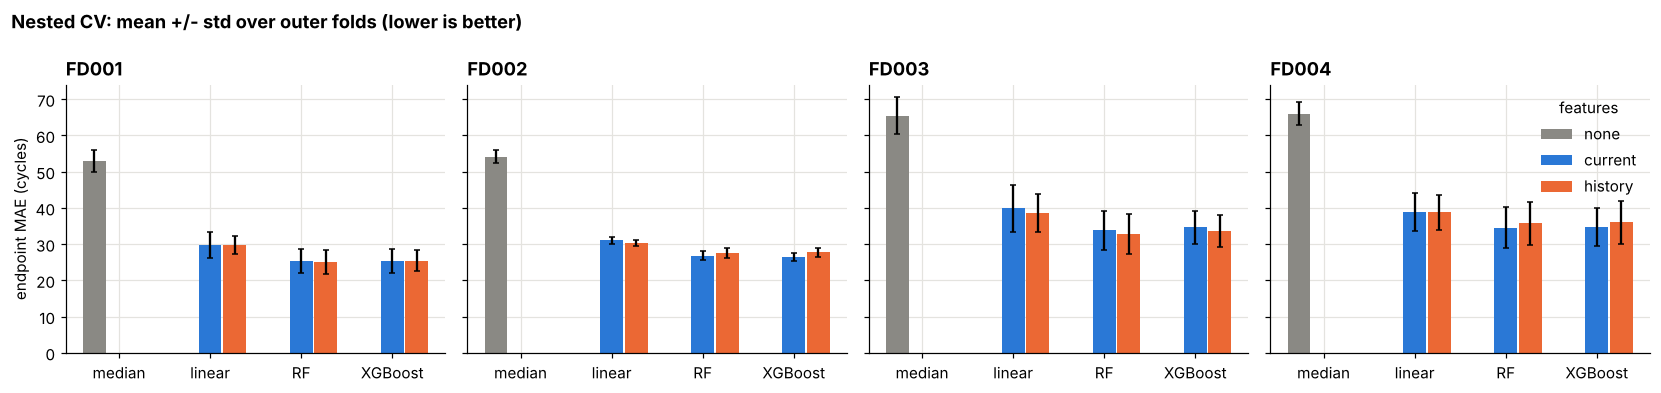

In [ ]:
# Figure: nested-CV MAE (mean +/- std over outer folds)
fig, axes = plt.subplots(1, len(SUBSETS), figsize=(3.8 * len(SUBSETS), 3.6), squeeze=False, sharey=True)
models = ["median", "linear", "random_forest", "xgboost"]
for i, subset in enumerate(SUBSETS):
    ax = axes[0, i]
    part = nested_summary[nested_summary["subset"] == subset]
    for j, feature_set in enumerate(["none", "current", "history"]):
        rows = part[part["feature_set"] == feature_set].set_index("model").reindex(models)
        x = np.arange(len(models)) + (j - 1) * 0.27
        ax.bar(x, rows["MAE_mean"], width=0.25, yerr=rows["MAE_std"], capsize=2,
               color=FEATURE_SET_COLORS[feature_set], label=feature_set)
    ax.set_xticks(np.arange(len(models)))
    ax.set_xticklabels(["median", "linear", "RF", "XGBoost"])
    ax.set_title(subset)
axes[0, 0].set_ylabel("endpoint MAE (cycles)")
axes[0, -1].legend(title="features")
fig.suptitle("Nested CV: mean +/- std over outer folds (lower is better)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_figure(fig, "nested_cv_mae.png")

## 6. OPTIONAL models (Ridge, MLP, LSTM)
These use the simpler single-split design (development engines -> validation endpoints), because nested CV for
neural networks would take far too long. Their validation scores are **not directly comparable** with the
nested-CV scores above; the official test results in section 8 compare all models on the same engines.

* **Ridge**: current and history features. **MLP**: history features. Both tuned with 3-fold grouped CV on development engines.
* **LSTM**: input = last 30 cycles of (cycle, 3 settings, kept sensors), standardized with development statistics;
  short histories are padded by repeating the first reading. Width, dropout and learning rate are tried with early
  stopping on the validation endpoints; the best epoch count is reused for the final fit.

In [ ]:
validation_rows, optional_params = [], {}
OPTIONAL_TABULAR = [("ridge", "current"), ("ridge", "history"), ("mlp", "history")]

if RUN_OPTIONAL_MODELS:
    for subset in SUBSETS:
        train = data[subset]["train"]
        dev = train[train["split"] == "development"]
        endpoints = train.loc[validation_endpoints[subset]]
        for name, feature_set in OPTIONAL_TABULAR:
            cols = columns_for(subset, feature_set)
            start = time.time()
            model, params = tune(name, dev[cols], dev["RUL"], dev["engine_key"])
            optional_params[(subset, name, feature_set)] = params
            validation_rows.append({"subset": subset, "model": name, "feature_set": feature_set,
                                    **score(endpoints["RUL"], predict_rul(model, endpoints[cols])),
                                    "seconds": time.time() - start})
        print(f"{subset}: Ridge and MLP done")
else:
    print("OPTIONAL models switched off.")

FD001: Ridge and MLP done


FD002: Ridge and MLP done


FD003: Ridge and MLP done


FD004: Ridge and MLP done


In [ ]:
# OPTIONAL: LSTM (needs TensorFlow)
HAVE_TF = False
if RUN_OPTIONAL_MODELS:
    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # hide TensorFlow start-up messages
    try:
        import tensorflow as tf
        from tensorflow import keras
        tf.get_logger().setLevel("ERROR")
        versions["tensorflow"] = tf.__version__
        HAVE_TF = True
    except ImportError:
        print("TensorFlow is not installed, so the LSTM is skipped (pip install tensorflow).")

LSTM_SPACE = {"units": [32, 64, 128], "dropout": [0.1, 0.2, 0.3], "learning_rate": [1e-3, 3e-3]}
RUL_SCALE = 100.0   # the LSTM learns RUL / 100 (easier to train); predictions are multiplied back


def lstm_columns(subset):
    return ["cycle"] + OP_SETTING_COLS + data[subset]["sensors"]


def make_windows(df, cols, scaler):
    # One window of the last HISTORY_WINDOW rows (past only) ending at every row of df.
    # df must be sorted by engine_key and cycle with a 0..n-1 index.
    values = scaler.transform(df[cols]).astype("float32")
    windows = np.zeros((len(df), HISTORY_WINDOW, len(cols)), dtype="float32")
    for positions in df.groupby("engine_key").indices.values():
        engine = values[positions]
        padded = np.vstack([np.repeat(engine[:1], HISTORY_WINDOW - 1, axis=0), engine])  # repeat first reading
        for i, position in enumerate(positions):
            windows[position] = padded[i:i + HISTORY_WINDOW]
    return windows


def build_lstm(n_features, units, dropout, learning_rate):
    model = keras.Sequential([
        keras.Input(shape=(HISTORY_WINDOW, n_features)),
        keras.layers.LSTM(units),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss="mae")
    return model


lstm_best, lstm_trials_table = {}, []
if HAVE_TF:
    for subset in SUBSETS:
        train = data[subset]["train"]
        cols = lstm_columns(subset)
        dev_mask = (train["split"] == "development").to_numpy()
        start = time.time()
        scaler = StandardScaler().fit(train.loc[dev_mask, cols])
        windows = make_windows(train, cols, scaler)
        window_seconds = time.time() - start
        val_idx = validation_endpoints[subset]
        X_dev, y_dev = windows[dev_mask], train["RUL"].to_numpy()[dev_mask] / RUL_SCALE
        X_val, y_val = windows[val_idx], train["RUL"].to_numpy()[val_idx] / RUL_SCALE

        best = None
        for params in ParameterSampler(LSTM_SPACE, n_iter=LSTM_TRIALS, random_state=RANDOM_STATE):
            keras.utils.set_random_seed(RANDOM_STATE)
            model = build_lstm(len(cols), **params)
            stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=LSTM_PATIENCE, restore_best_weights=True)
            start = time.time()
            history = model.fit(X_dev, y_dev, validation_data=(X_val, y_val), epochs=LSTM_MAX_EPOCHS,
                                batch_size=LSTM_BATCH, callbacks=[stop], verbose=0)
            val_mae = min(history.history["val_loss"]) * RUL_SCALE
            best_epoch = int(np.argmin(history.history["val_loss"])) + 1
            lstm_trials_table.append({"subset": subset, **params, "best_epoch": best_epoch,
                                      "validation_endpoint_MAE": val_mae, "seconds": time.time() - start})
            if best is None or val_mae < best["val_mae"]:
                best = {"params": params, "best_epoch": best_epoch, "val_mae": val_mae,
                        "history": history.history, "model": model}

        prediction = np.clip(best["model"].predict(X_val, verbose=0).ravel() * RUL_SCALE, 0, None)
        validation_rows.append({"subset": subset, "model": "lstm", "feature_set": "sequence",
                                **score(train["RUL"].to_numpy()[val_idx], prediction), "seconds": np.nan})
        best["window_seconds"] = window_seconds
        lstm_best[subset] = best
        print(f"{subset}: best LSTM {best['params']}, epoch {best['best_epoch']}, validation MAE {best['val_mae']:.2f}")
    pd.DataFrame(lstm_trials_table).to_csv(TABLE_DIR / "lstm_tuning_trials.csv", index=False)

validation_results = pd.DataFrame(validation_rows)
if len(validation_results):
    validation_results.to_csv(TABLE_DIR / "optional_models_validation.csv", index=False)
    display(validation_results)

I0000 00:00:1795141698.883995     165 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795141698.884441     165 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795141700.020442     165 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795141700.020784     165 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


FD001: best LSTM {'units': 32, 'learning_rate': 0.001, 'dropout': 0.1}, epoch 4, validation MAE 24.32


FD002: best LSTM {'units': 32, 'learning_rate': 0.001, 'dropout': 0.1}, epoch 17, validation MAE 23.83


FD003: best LSTM {'units': 128, 'learning_rate': 0.001, 'dropout': 0.2}, epoch 2, validation MAE 27.20


FD004: best LSTM {'units': 128, 'learning_rate': 0.001, 'dropout': 0.2}, epoch 9, validation MAE 35.85


,subset,model,feature_set,MAE,RMSE,near_failure_n,near_failure_MAE,near_failure_over10_pct,seconds
0,FD001,ridge,current,32.13,42.54,9,10.52,33.33,0.19
1,FD001,ridge,history,31.30,42.70,9,7.19,11.11,0.50
2,FD001,mlp,history,24.60,37.69,9,4.14,11.11,80.92
3,FD002,ridge,current,31.54,40.71,39,17.25,46.15,0.35
4,FD002,ridge,history,30.10,39.47,39,13.64,41.03,1.22
5,FD002,mlp,history,28.57,39.03,39,9.08,25.64,189.31
6,FD003,ridge,current,36.86,50.43,8,8.82,12.50,0.21
7,FD003,ridge,history,35.43,48.74,8,7.16,25.00,0.52
8,FD003,mlp,history,37.20,55.92,8,12.93,25.00,101.83
9,FD004,ridge,current,40.63,52.63,31,16.45,45.16,0.42


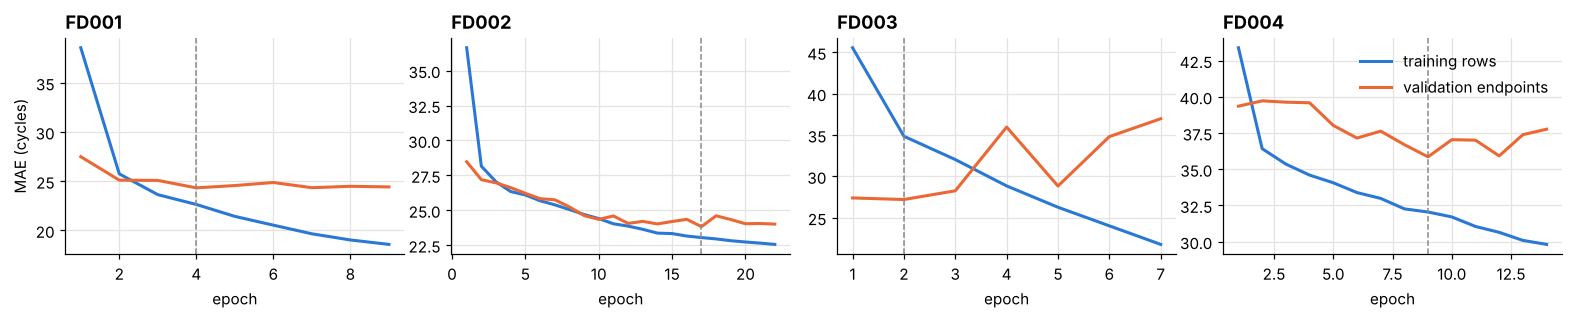

In [ ]:
# OPTIONAL: LSTM learning curves (training vs. validation-endpoint MAE per epoch)
if lstm_best:
    fig, axes = plt.subplots(1, len(lstm_best), figsize=(3.6 * len(lstm_best), 3.0), squeeze=False)
    for i, (subset, best) in enumerate(lstm_best.items()):
        ax = axes[0, i]
        epochs = np.arange(1, len(best["history"]["loss"]) + 1)
        ax.plot(epochs, np.array(best["history"]["loss"]) * RUL_SCALE, color=BLUE, lw=2, label="training rows")
        ax.plot(epochs, np.array(best["history"]["val_loss"]) * RUL_SCALE, color=ORANGE, lw=2, label="validation endpoints")
        ax.axvline(best["best_epoch"], color="#8a8984", ls="--", lw=1)
        ax.set_title(subset)
        ax.set_xlabel("epoch")
    axes[0, 0].set_ylabel("MAE (cycles)")
    axes[0, -1].legend()
    fig.tight_layout()
    save_figure(fig, "lstm_learning_curves.png")

## 7. Final fit and official test (used once)
All choices are now frozen. For every model:
1. tune once more with 3-fold grouped CV on **all** training engines (core models) or reuse the settings found on the
   development engines (OPTIONAL models; LSTM uses its validation epoch count),
2. refit on all training engines,
3. predict **once** at each test engine's last observed cycle and compare with the official RUL label.

RF, XGBoost and LSTM are repeated with 3 seeds; the main table uses seed 42 and reports the spread over seeds.

In [ ]:
test_predictions, timing_rows, final_params, final_models = [], [], {}, {}


def add_predictions(subset, name, feature_set, seed, last_rows, prediction):
    for engine, true_rul, predicted in zip(last_rows["engine_key"], last_rows["RUL"], prediction):
        test_predictions.append({"subset": subset, "engine_key": engine, "model": name, "feature_set": feature_set,
                                 "seed": seed, "true_RUL": true_rul, "predicted_RUL": predicted,
                                 "error": predicted - true_rul})


def save_model(model, subset, name, feature_set):
    if name == "random_forest" and not SAVE_RF_MODELS:
        return
    with open(MODEL_DIR / f"{subset}_{name}_{feature_set}.pkl", "wb") as file:
        pickle.dump(model, file)


final_start = time.time()
for subset in SUBSETS:
    train, test = data[subset]["train"], data[subset]["test"]
    last_rows = test.groupby("engine_key").tail(1)   # final observed cycle of every test engine
    runs = [(name, fs, "core") for name, fs in CORE_RUNS]
    if RUN_OPTIONAL_MODELS:
        runs += [(name, fs, "optional") for name, fs in OPTIONAL_TABULAR]

    for name, feature_set, kind in runs:
        cols = columns_for(subset, feature_set)
        start = time.time()
        if kind == "core":
            _, params = tune(name, train[cols], train["RUL"], train["engine_key"], refit=False)
        else:
            params = optional_params[(subset, name, feature_set)]
        tune_seconds = time.time() - start
        final_params[(subset, name, feature_set)] = params

        for seed in (SEEDS if name in ("random_forest", "xgboost") else [RANDOM_STATE]):
            model = make_model(name, seed).set_params(**params)
            start = time.time()
            model.fit(train[cols], train["RUL"])
            fit_seconds = time.time() - start
            start = time.time()
            prediction = predict_rul(model, last_rows[cols])
            predict_seconds = time.time() - start
            add_predictions(subset, name, feature_set, seed, last_rows, prediction)
            if seed == RANDOM_STATE:
                final_models[(subset, name, feature_set)] = model
                save_model(model, subset, name, feature_set)
                timing_rows.append({"subset": subset, "model": name, "feature_set": feature_set,
                                    "load_seconds": prep_seconds[subset], "tune_seconds": tune_seconds,
                                    "fit_seconds": fit_seconds, "predict_seconds": predict_seconds})
    print(f"{subset}: tabular models done ({(time.time() - final_start) / 60:.1f} min total)")

FD001: tabular models done (3.5 min total)


FD002: tabular models done (12.6 min total)


FD003: tabular models done (16.6 min total)


FD004: tabular models done (27.9 min total)


In [ ]:
# OPTIONAL: final LSTM on all training engines, 3 seeds
if lstm_best:
    for subset, best in lstm_best.items():
        train, test = data[subset]["train"], data[subset]["test"]
        cols = lstm_columns(subset)
        start = time.time()
        scaler = StandardScaler().fit(train[cols])
        X_train = make_windows(train, cols, scaler)
        last_idx = test.groupby("engine_key").tail(1).index.to_numpy()
        X_test = make_windows(test, cols, scaler)[last_idx]
        window_seconds = time.time() - start
        last_rows = test.loc[last_idx]
        for seed in SEEDS:
            keras.utils.set_random_seed(seed)
            model = build_lstm(len(cols), **best["params"])
            start = time.time()
            model.fit(X_train, train["RUL"].to_numpy() / RUL_SCALE, epochs=best["best_epoch"],
                      batch_size=LSTM_BATCH, verbose=0)
            fit_seconds = time.time() - start
            start = time.time()
            prediction = np.clip(model.predict(X_test, verbose=0).ravel() * RUL_SCALE, 0, None)
            predict_seconds = time.time() - start
            add_predictions(subset, "lstm", "sequence", seed, last_rows, prediction)
            if seed == RANDOM_STATE:
                model.save(MODEL_DIR / f"{subset}_lstm_sequence.keras")
                timing_rows.append({"subset": subset, "model": "lstm", "feature_set": "sequence",
                                    "load_seconds": prep_seconds[subset] + window_seconds,
                                    "tune_seconds": sum(t["seconds"] for t in lstm_trials_table if t["subset"] == subset),
                                    "fit_seconds": fit_seconds, "predict_seconds": predict_seconds})
        final_params[(subset, "lstm", "sequence")] = {**best["params"], "epochs": best["best_epoch"]}
        print(f"{subset}: LSTM done")

predictions = pd.DataFrame(test_predictions)
predictions.to_csv(PRED_DIR / "test_predictions_all_seeds.csv", index=False)
predictions[predictions["seed"] == RANDOM_STATE].to_csv(PRED_DIR / "test_predictions_engine_level.csv", index=False)
timing = pd.DataFrame(timing_rows)

FD001: LSTM done


FD002: LSTM done


FD003: LSTM done


FD004: LSTM done


## 8. Results on the official test set

In [ ]:
result_rows = []
for (subset, name, feature_set), group in predictions.groupby(["subset", "model", "feature_set"]):
    main = group[group["seed"] == RANDOM_STATE]
    seed_maes = group.groupby("seed").apply(lambda g: np.mean(np.abs(g["error"])))
    result_rows.append({"subset": subset, "model": name, "feature_set": feature_set,
                        **score(main["true_RUL"], main["predicted_RUL"]),
                        **bootstrap_ci(main["true_RUL"], main["predicted_RUL"]),
                        "MAE_seed_mean": seed_maes.mean(), "MAE_seed_std": seed_maes.std(ddof=0),
                        "n_seeds": len(seed_maes)})
results = pd.DataFrame(result_rows).merge(timing, on=["subset", "model", "feature_set"], how="left")
results["few_near_failure_cases"] = results["near_failure_n"] < FEW_CASES
results["model"] = pd.Categorical(results["model"], MODEL_ORDER, ordered=True)
results = results.sort_values(["subset", "model", "feature_set"]).reset_index(drop=True)
results.to_csv(TABLE_DIR / "test_results_main.csv", index=False)   # full precision

main_columns = ["subset", "model", "feature_set", "MAE", "MAE_CI_low", "MAE_CI_high", "RMSE",
                "near_failure_n", "near_failure_MAE", "near_failure_over10_pct", "MAE_seed_std",
                "fit_seconds", "predict_seconds"]
display(results[main_columns].round(2))

few = results.loc[results["few_near_failure_cases"], "subset"].unique()
if len(few):
    print(f"Note: fewer than {FEW_CASES} near-failure test engines in {list(few)}; near-failure numbers there are unstable.")

# Equal-weight average across subsets (only when all four subsets were run)
if len(SUBSETS) == 4:
    average = (results.groupby(["model", "feature_set"], observed=True)
               [["MAE", "RMSE", "near_failure_MAE", "near_failure_over10_pct", "MAE_seed_std"]]
               .mean().reset_index().sort_values("MAE"))
    average.to_csv(TABLE_DIR / "test_results_equal_weight_average.csv", index=False)
    display(average.round(2))

# Test results of the core model picked per subset by nested CV (picked BEFORE looking at the test set)
chosen = best_core[["subset", "model", "feature_set"]].merge(
    results.assign(model=results["model"].astype(str)), on=["subset", "model", "feature_set"])
chosen.to_csv(TABLE_DIR / "test_results_chosen_core.csv", index=False)
display(chosen[main_columns].round(2))

,subset,model,feature_set,MAE,MAE_CI_low,MAE_CI_high,RMSE,near_failure_n,near_failure_MAE,near_failure_over10_pct,MAE_seed_std,fit_seconds,predict_seconds
0,FD001,median,none,39.08,32.57,45.28,49.82,25,85.28,100.00,0.00,0.00,0.00
1,FD001,linear,current,25.71,22.57,29.22,30.98,25,23.20,64.00,0.00,0.01,0.00
2,FD001,linear,history,23.20,20.16,26.21,27.99,25,17.95,48.00,0.00,0.04,0.00
3,FD001,random_forest,current,18.52,15.58,21.88,24.96,25,10.08,28.00,0.14,1.33,0.05
4,FD001,random_forest,history,19.38,16.16,22.91,26.00,25,5.50,12.00,0.46,2.62,0.03
5,FD001,xgboost,current,18.41,15.22,21.98,25.16,25,8.87,24.00,0.17,0.25,0.00
6,FD001,xgboost,history,18.05,14.87,21.55,24.72,25,4.04,12.00,0.15,5.83,0.01
7,FD001,ridge,current,25.37,22.16,28.93,30.69,25,22.96,64.00,0.00,0.01,0.00
8,FD001,ridge,history,23.30,20.29,26.34,28.07,25,17.71,52.00,0.00,0.02,0.00
9,FD001,mlp,history,21.97,18.81,25.61,27.86,25,9.42,28.00,0.00,5.92,0.00


,model,feature_set,MAE,RMSE,near_failure_MAE,near_failure_over10_pct,MAE_seed_std
10,lstm,sequence,19.64,28.69,5.60,14.19,1.05
6,xgboost,history,22.21,31.82,5.81,18.87,0.17
5,xgboost,current,23.19,32.04,7.78,18.69,0.14
3,random_forest,current,23.54,32.61,8.59,25.51,0.19
4,random_forest,history,23.71,33.10,7.75,24.16,0.19
9,mlp,history,24.99,34.21,11.74,32.81,0.00
8,ridge,history,30.27,38.48,19.26,46.35,0.00
2,linear,history,30.41,38.46,20.57,46.50,0.00
7,ridge,current,32.94,40.86,21.90,58.84,0.00
1,linear,current,33.04,41.01,22.06,60.50,0.00


,subset,model,feature_set,MAE,MAE_CI_low,MAE_CI_high,RMSE,near_failure_n,near_failure_MAE,near_failure_over10_pct,MAE_seed_std,fit_seconds,predict_seconds
0,FD001,random_forest,history,19.38,16.16,22.91,26.00,25,5.50,12.00,0.46,2.62,0.03
1,FD002,xgboost,current,19.96,17.79,22.25,27.52,61,6.82,13.11,0.06,1.28,0.00
2,FD003,random_forest,history,26.66,21.11,33.07,40.29,20,5.56,15.00,0.21,1.66,0.05
3,FD004,random_forest,current,27.61,24.51,30.78,37.76,53,10.42,37.74,0.20,1.49,0.02


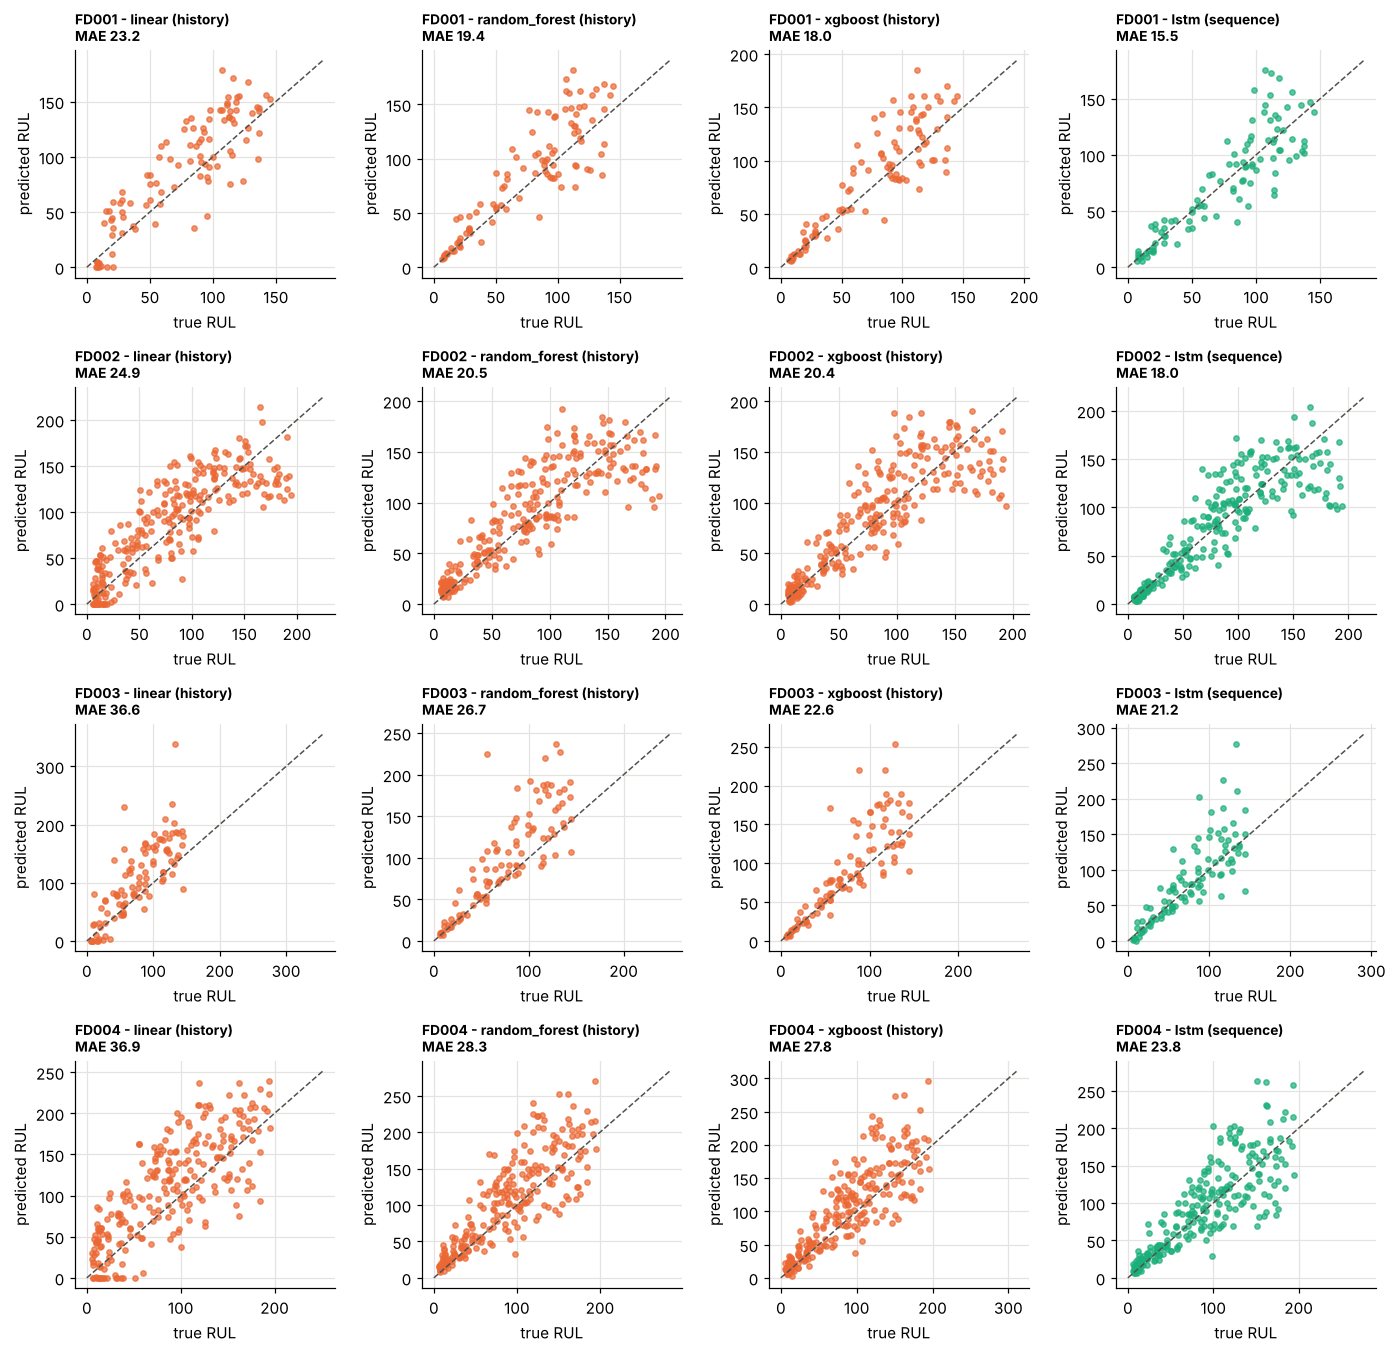

In [ ]:
# Predicted vs. actual RUL on the test engines (seed 42)
show = [("linear", "history"), ("random_forest", "history"), ("xgboost", "history")]
if lstm_best:
    show.append(("lstm", "sequence"))
main_predictions = predictions[predictions["seed"] == RANDOM_STATE]
fig, axes = plt.subplots(len(SUBSETS), len(show), figsize=(3.2 * len(show), 3.1 * len(SUBSETS)), squeeze=False)
for i, subset in enumerate(SUBSETS):
    for j, (name, feature_set) in enumerate(show):
        ax = axes[i, j]
        part = main_predictions[(main_predictions["subset"] == subset) & (main_predictions["model"] == name)
                                & (main_predictions["feature_set"] == feature_set)]
        ax.scatter(part["true_RUL"], part["predicted_RUL"], s=12, alpha=0.7, color=FEATURE_SET_COLORS[feature_set])
        limit = max(part["true_RUL"].max(), part["predicted_RUL"].max()) * 1.05
        ax.plot([0, limit], [0, limit], color="#52514e", lw=1, ls="--")
        mae = np.mean(np.abs(part["error"]))
        ax.set_title(f"{subset} - {name} ({feature_set})\nMAE {mae:.1f}", fontsize=9)
        ax.set_xlabel("true RUL")
        ax.set_ylabel("predicted RUL")
fig.tight_layout()
save_figure(fig, "test_predicted_vs_actual.png")

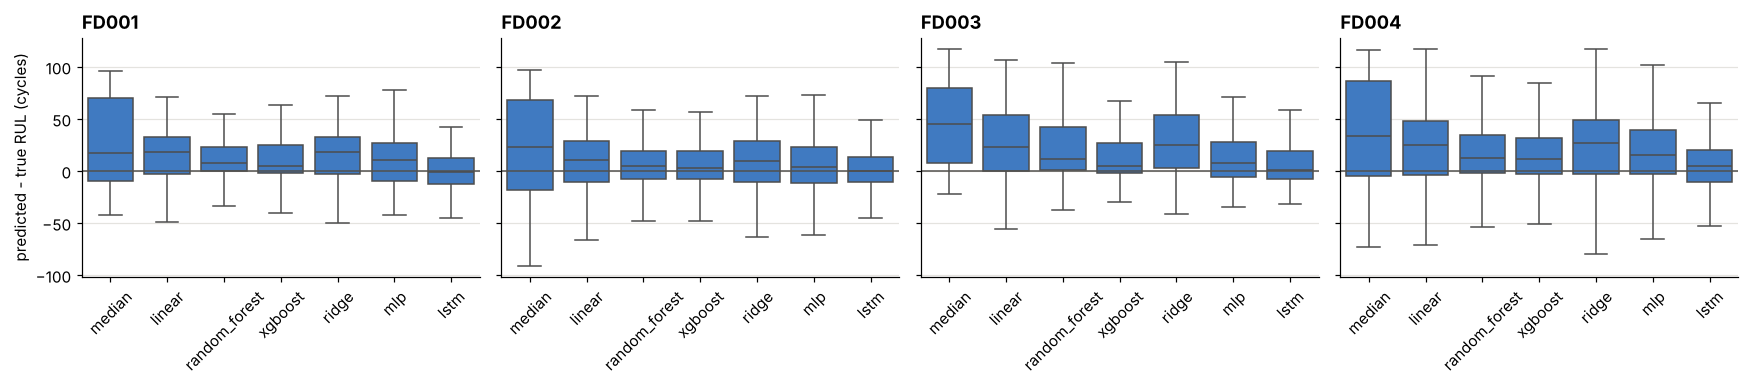

In [ ]:
# Signed error distribution on the test engines (positive = predicted too much remaining life)
order = [m for m in MODEL_ORDER if m in main_predictions["model"].unique()]
plot_df = main_predictions[main_predictions["feature_set"].isin(["none", "history", "sequence"])]
fig, axes = plt.subplots(1, len(SUBSETS), figsize=(4.0 * len(SUBSETS), 3.6), squeeze=False, sharey=True)
for i, subset in enumerate(SUBSETS):
    sns.boxplot(data=plot_df[plot_df["subset"] == subset], x="model", y="error", order=order,
                color=BLUE, showfliers=False, ax=axes[0, i])
    axes[0, i].axhline(0, color="#52514e", lw=1)
    axes[0, i].set_title(subset)
    axes[0, i].set_xlabel("")
    axes[0, i].tick_params(axis="x", rotation=45)
axes[0, 0].set_ylabel("predicted - true RUL (cycles)")
fig.tight_layout()
save_figure(fig, "test_error_distribution.png")

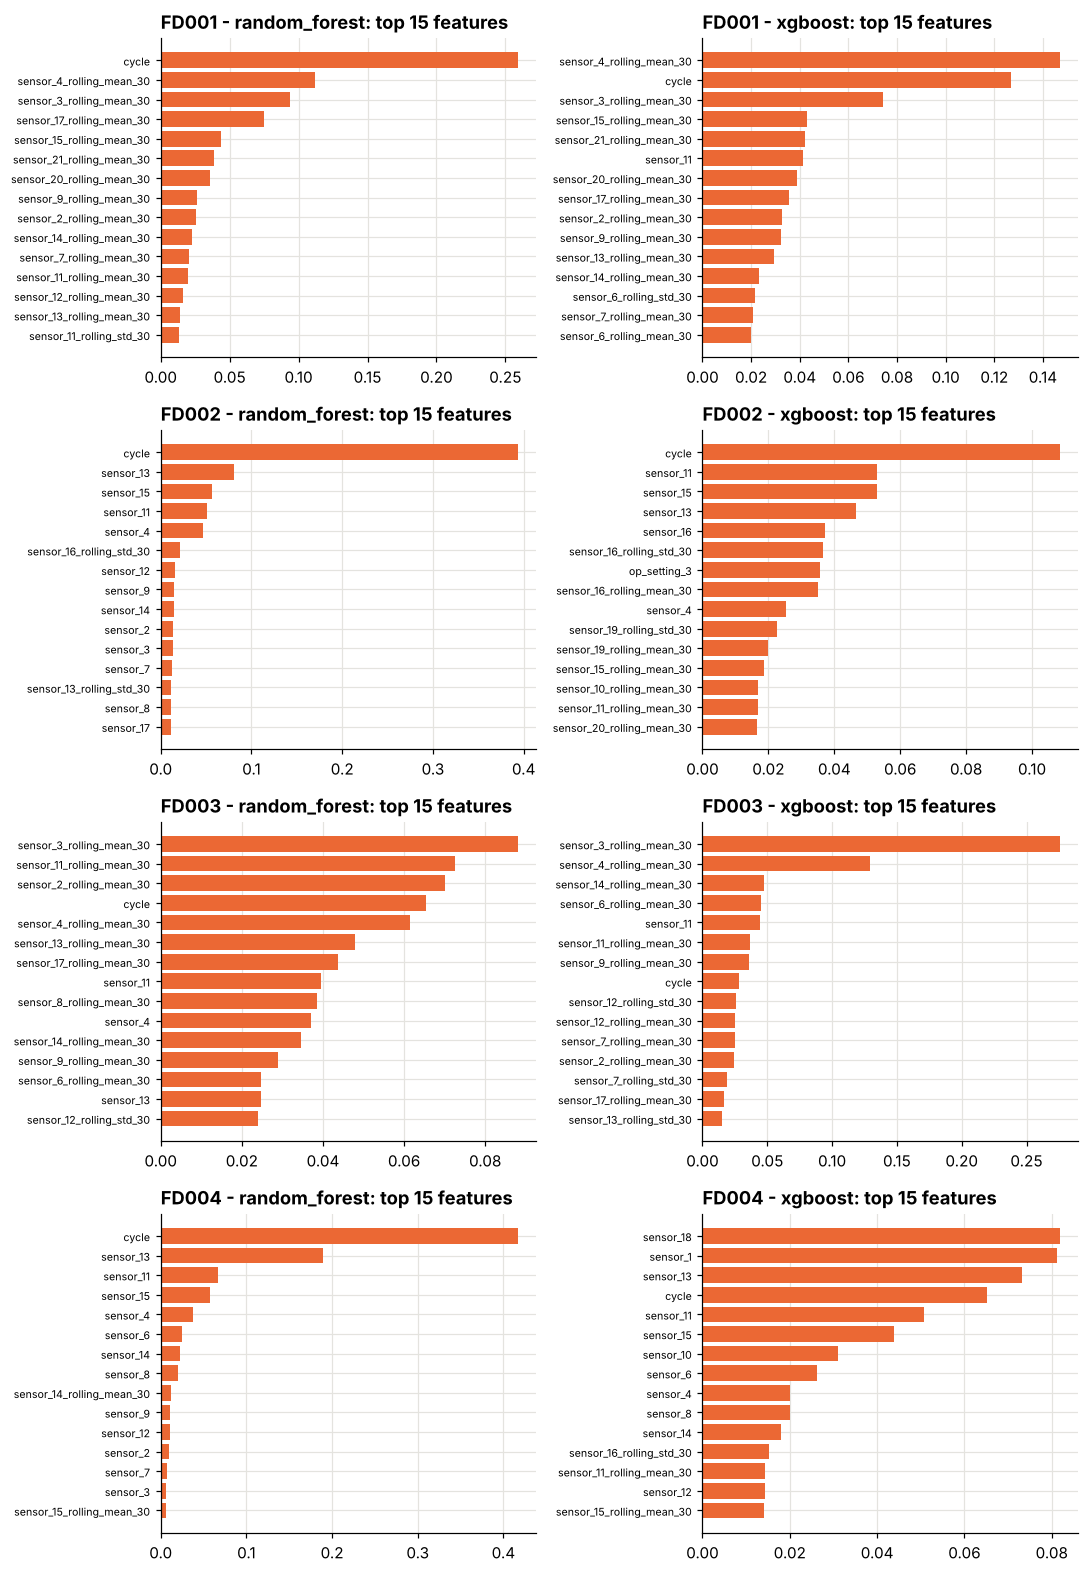

Feature importance describes what the model uses, not what causes failure.


In [ ]:
# Feature importance of the final tree models (history features, seed 42)
fig, axes = plt.subplots(len(SUBSETS), 2, figsize=(10, 3.6 * len(SUBSETS)), squeeze=False)
for i, subset in enumerate(SUBSETS):
    cols = data[subset]["features"]["history"]
    for j, name in enumerate(["random_forest", "xgboost"]):
        importance = pd.Series(final_models[(subset, name, "history")].feature_importances_, index=cols)
        top = importance.sort_values().tail(15)
        axes[i, j].barh(top.index, top.values, color=ORANGE)
        axes[i, j].set_title(f"{subset} - {name}: top 15 features")
        axes[i, j].tick_params(axis="y", labelsize=7)
fig.tight_layout()
save_figure(fig, "feature_importance.png")
print("Feature importance describes what the model uses, not what causes failure.")

## 9. OPTIONAL extension: RUL cap at 130 and per-condition normalization
* **cap130**: training labels above 130 are set to 130 ("healthy"). Scores always use the **true uncapped** labels.
* **condition_norm** (FD002 / FD004 only): each sensor is standardized inside its operating condition (KMeans on the
  settings, learned on the fitting engines only), then the 30-cycle history features are rebuilt from the normalized sensors.

To keep the run time reasonable the hyperparameters are **not re-tuned**: each model reuses its final settings from
section 7 (history features, seed 42). Every variant is scored on the validation endpoints (fit on development
engines) and on the official test set (fit on all training engines).

In [ ]:
def add_history(df, sensors):
    # Same definitions as scripts/3_feature_engineer.py: past-only rolling mean, rolling std and change
    df = df.sort_values(["engine_key", "cycle"]).copy()
    for sensor in sensors:
        grouped = df.groupby("engine_key")[sensor]
        df[f"{sensor}_rolling_mean_{HISTORY_WINDOW}"] = grouped.transform(
            lambda values: values.rolling(window=HISTORY_WINDOW, min_periods=1).mean())
        df[f"{sensor}_rolling_std_{HISTORY_WINDOW}"] = grouped.transform(
            lambda values: values.rolling(window=HISTORY_WINDOW, min_periods=2).std()).fillna(0.0)
        df[f"{sensor}_change"] = grouped.diff().fillna(0.0)
    return df


def prepare_variant(fit_df, other_df, subset, normalize):
    # Return (fit_df, other_df), with per-condition normalized sensors and rebuilt history if normalize=True
    if not normalize:
        return fit_df, other_df
    sensors = data[subset]["sensors"]
    normalizer = fit_condition_normalizer(fit_df, sensors, N_CONDITIONS[subset])
    return (add_history(apply_condition_normalizer(fit_df, sensors, normalizer), sensors),
            add_history(apply_condition_normalizer(other_df, sensors, normalizer), sensors))


extension_rows = []
if RUN_OPTIONAL_EXTENSION:
    for subset in SUBSETS:
        train, test = data[subset]["train"], data[subset]["test"]
        cols = data[subset]["features"]["history"]
        variants = [("original", False, False), ("cap130", True, False)]
        if N_CONDITIONS[subset] > 1:
            variants += [("condition_norm", False, True), ("cap130+condition_norm", True, True)]
        stages = {
            "validation": (train[train["split"] == "development"], train[train["split"] == "validation"]),
            "test": (train, test),
        }
        for stage, (fit_raw, other_raw) in stages.items():
            for variant, cap, normalize in variants:
                fit_df, other_df = prepare_variant(fit_raw, other_raw, subset, normalize)
                rows = other_df.loc[validation_endpoints[subset]] if stage == "validation" else other_df.groupby("engine_key").tail(1)
                target = fit_df["RUL"].clip(upper=RUL_CAP) if cap else fit_df["RUL"]
                for name in ["linear", "random_forest", "xgboost"]:
                    model = make_model(name).set_params(**final_params[(subset, name, "history")])
                    model.fit(fit_df[cols], target)
                    extension_rows.append({"subset": subset, "stage": stage, "variant": variant, "model": name,
                                           **score(rows["RUL"], predict_rul(model, rows[cols]))})
        print(f"{subset}: extension done")

    extension = pd.DataFrame(extension_rows)
    extension.to_csv(TABLE_DIR / "optional_extension_results.csv", index=False)
    for metric in ["MAE", "RMSE", "near_failure_MAE", "near_failure_over10_pct"]:
        print(metric)
        display(extension.pivot_table(index=["subset", "model"], columns=["stage", "variant"], values=metric).round(2))
else:
    print("OPTIONAL extension switched off.")

FD001: extension done


FD002: extension done


FD003: extension done


FD004: extension done


MAE


stage                  test                                                \
variant              cap130 cap130+condition_norm condition_norm original   
subset model                                                                
FD001  linear         14.87                   NaN            NaN    23.20   
       random_forest  13.44                   NaN            NaN    19.38   
       xgboost        13.20                   NaN            NaN    18.05   
FD002  linear         22.35                 21.38          24.34    24.92   
       random_forest  20.03                 18.99          20.52    20.47   
       xgboost        19.12                 17.89          19.77    20.40   
FD003  linear         15.66                   NaN            NaN    36.58   
       random_forest  13.52                   NaN            NaN    26.66   
       xgboost        12.42                   NaN            NaN    22.63   
FD004  linear         26.14                 25.26          36.32    36.94   
       random_forest  22.24                 20.57          26.64    28.32   
       xgboost        20.80                 18.92          25.56    27.77   

stage                validation                                                
variant                  cap130 cap130+condition_norm condition_norm original  
subset model                                                                   
FD001  linear             32.19                   NaN            NaN    31.58  
       random_forest      29.36                   NaN            NaN    27.67  
       xgboost            29.15                   NaN            NaN    28.37  
FD002  linear             30.58                 29.71          29.49    30.26  
       random_forest      30.09                 29.11          26.47    28.21  
       xgboost            29.01                 28.05          25.67    28.32  
FD003  linear             34.09                   NaN            NaN    34.71  
       random_forest      31.23                   NaN            NaN    32.56  
       xgboost            30.91                   NaN            NaN    30.68  
FD004  linear             47.99                 47.65          40.54    40.69  
       random_forest      47.86                 46.70          36.81    36.67  
       xgboost            46.68                 46.73          36.22    36.46

... (2 outputs left out)

near_failure_MAE


stage                  test                                                \
variant              cap130 cap130+condition_norm condition_norm original   
subset model                                                                
FD001  linear         14.35                   NaN            NaN    17.95   
       random_forest   5.11                   NaN            NaN     5.50   
       xgboost         3.76                   NaN            NaN     4.04   
FD002  linear         14.81                 11.52          14.85    17.44   
       random_forest   8.99                  5.81           5.72     8.25   
       xgboost         6.15                  3.76           3.86     6.65   
FD003  linear         11.15                   NaN            NaN    18.97   
       random_forest   5.11                   NaN            NaN     5.56   
       xgboost         3.16                   NaN            NaN     3.47   
FD004  linear         19.27                 17.66          25.13    27.91   
       random_forest  11.78                  8.77           8.96    11.68   
       xgboost         8.27                  5.86           6.82     9.10   

stage                validation                                                
variant                  cap130 cap130+condition_norm condition_norm original  
subset model                                                                   
FD001  linear              5.13                   NaN            NaN     6.87  
       random_forest       2.78                   NaN            NaN     2.39  
       xgboost             3.20                   NaN            NaN     2.55  
FD002  linear             12.88                  9.46          12.30    13.42  
       random_forest       8.96                  5.01           4.58     9.46  
       xgboost             6.80                  4.46           4.79     7.17  
FD003  linear             12.88                   NaN            NaN     8.57  
       random_forest       2.53                   NaN            NaN     2.65  
       xgboost             2.68                   NaN            NaN     3.27  
FD004  linear             15.97                 13.42          17.37    19.02  
       random_forest      10.24                  6.76           6.82    10.71  
       xgboost             6.95                  5.57           6.43     8.55

near_failure_over10_pct


stage                  test                                                \
variant              cap130 cap130+condition_norm condition_norm original   
subset model                                                                
FD001  linear         52.00                   NaN            NaN    48.00   
       random_forest  12.00                   NaN            NaN    12.00   
       xgboost        12.00                   NaN            NaN    12.00   
FD002  linear         49.18                 39.34          37.70    42.62   
       random_forest  27.87                 13.11          11.48    26.23   
       xgboost        14.75                  4.92           6.56    16.39   
FD003  linear         35.00                   NaN            NaN    35.00   
       random_forest  15.00                   NaN            NaN    15.00   
       xgboost         5.00                   NaN            NaN    15.00   
FD004  linear         54.72                 56.60          56.60    60.38   
       random_forest  41.51                 30.19          32.08    43.40   
       xgboost        26.42                  9.43          15.09    32.08   

stage                validation                                                
variant                  cap130 cap130+condition_norm condition_norm original  
subset model                                                                   
FD001  linear             11.11                   NaN            NaN    11.11  
       random_forest       0.00                   NaN            NaN     0.00  
       xgboost             0.00                   NaN            NaN     0.00  
FD002  linear             43.59                 23.08          25.64    38.46  
       random_forest      35.90                 10.26           5.13    38.46  
       xgboost            23.08                  5.13           5.13    28.21  
FD003  linear             50.00                   NaN            NaN    37.50  
       random_forest       0.00                   NaN            NaN     0.00  
       xgboost            12.50                   NaN            NaN    12.50  
FD004  linear             48.39                 41.94          45.16    51.61  
       random_forest      35.48                 19.35          19.35    38.71  
       xgboost            22.58                 12.90          16.13    35.48

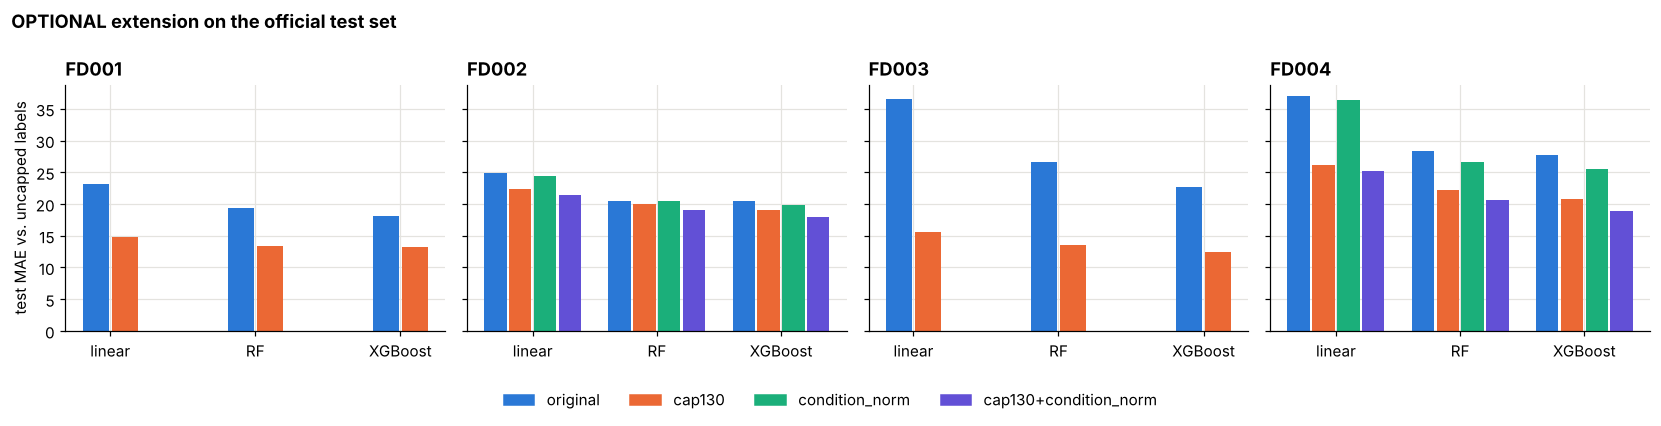

In [ ]:
if RUN_OPTIONAL_EXTENSION:
    variant_colors = {"original": BLUE, "cap130": ORANGE, "condition_norm": AQUA, "cap130+condition_norm": VIOLET}
    test_part = extension[extension["stage"] == "test"]
    fig, axes = plt.subplots(1, len(SUBSETS), figsize=(3.8 * len(SUBSETS), 3.4), squeeze=False, sharey=True)
    for i, subset in enumerate(SUBSETS):
        part = test_part[test_part["subset"] == subset]
        variants = [v for v in variant_colors if v in part["variant"].unique()]
        for j, variant in enumerate(variants):
            rows = part[part["variant"] == variant].set_index("model").reindex(["linear", "random_forest", "xgboost"])
            x = np.arange(3) + (j - (len(variants) - 1) / 2) * 0.2
            axes[0, i].bar(x, rows["MAE"], width=0.18, color=variant_colors[variant], label=variant)
        axes[0, i].set_xticks(np.arange(3))
        axes[0, i].set_xticklabels(["linear", "RF", "XGBoost"])
        axes[0, i].set_title(subset)
    axes[0, 0].set_ylabel("test MAE vs. uncapped labels")
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in variant_colors.values()]
    fig.suptitle("OPTIONAL extension on the official test set", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    fig.legend(handles, variant_colors.keys(), loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.0))
    save_figure(fig, "optional_extension_test_mae.png")

## 10. Maintenance-priority view (research demonstration)
Test engines ranked by predicted RUL, using the best core model per subset **as chosen by nested CV** (not by the
test score). Bands are study thresholds, not approved maintenance limits. Point estimates only: no prediction
intervals were developed, so the ranking must not be used for real maintenance decisions.

FD001 - model: random_forest (history)


,rank,engine_key,predicted_RUL,priority,true_RUL,error
0,1,FD001_34,8.0,1 - inspect soon,7,1.0
1,2,FD001_81,8.5,1 - inspect soon,8,0.5
2,3,FD001_68,10.0,1 - inspect soon,8,2.0
3,4,FD001_82,10.9,1 - inspect soon,9,1.9
4,5,FD001_31,11.7,1 - inspect soon,8,3.7
5,6,FD001_76,12.0,1 - inspect soon,10,2.0
6,7,FD001_35,12.3,1 - inspect soon,11,1.3
7,8,FD001_42,13.2,1 - inspect soon,10,3.2
8,9,FD001_56,14.6,1 - inspect soon,15,-0.4
9,10,FD001_20,15.1,1 - inspect soon,16,-0.9


FD002 - model: xgboost (current)


,rank,engine_key,predicted_RUL,priority,true_RUL,error
0,1,FD002_210,0.0,1 - inspect soon,8,-8.0
1,2,FD002_134,1.0,1 - inspect soon,9,-8.0
2,3,FD002_124,1.4,1 - inspect soon,7,-5.6
3,4,FD002_14,2.1,1 - inspect soon,11,-8.9
4,5,FD002_227,3.3,1 - inspect soon,14,-10.7
5,6,FD002_159,3.8,1 - inspect soon,9,-5.2
6,7,FD002_44,4.2,1 - inspect soon,6,-1.8
7,8,FD002_90,4.4,1 - inspect soon,8,-3.6
8,9,FD002_5,5.1,1 - inspect soon,15,-9.9
9,10,FD002_231,6.2,1 - inspect soon,8,-1.8


FD003 - model: random_forest (history)


,rank,engine_key,predicted_RUL,priority,true_RUL,error
0,1,FD003_82,7.3,1 - inspect soon,6,1.3
1,2,FD003_94,7.3,1 - inspect soon,10,-2.7
2,3,FD003_99,9.2,1 - inspect soon,8,1.2
3,4,FD003_46,9.7,1 - inspect soon,7,2.7
4,5,FD003_39,9.8,1 - inspect soon,8,1.8
5,6,FD003_24,10.3,1 - inspect soon,9,1.3
6,7,FD003_92,14.8,1 - inspect soon,14,0.8
7,8,FD003_98,17.2,1 - inspect soon,17,0.2
8,9,FD003_21,17.4,1 - inspect soon,18,-0.6
9,10,FD003_50,17.9,1 - inspect soon,11,6.9


FD004 - model: random_forest (current)


,rank,engine_key,predicted_RUL,priority,true_RUL,error
0,1,FD004_58,6.6,1 - inspect soon,8,-1.4
1,2,FD004_12,9.5,1 - inspect soon,7,2.5
2,3,FD004_135,9.9,1 - inspect soon,7,2.9
3,4,FD004_173,9.9,1 - inspect soon,8,1.9
4,5,FD004_183,10.0,1 - inspect soon,15,-5.0
5,6,FD004_184,11.2,1 - inspect soon,10,1.2
6,7,FD004_174,11.9,1 - inspect soon,10,1.9
7,8,FD004_202,12.7,1 - inspect soon,13,-0.3
8,9,FD004_158,12.8,1 - inspect soon,6,6.8
9,10,FD004_103,13.0,1 - inspect soon,9,4.0


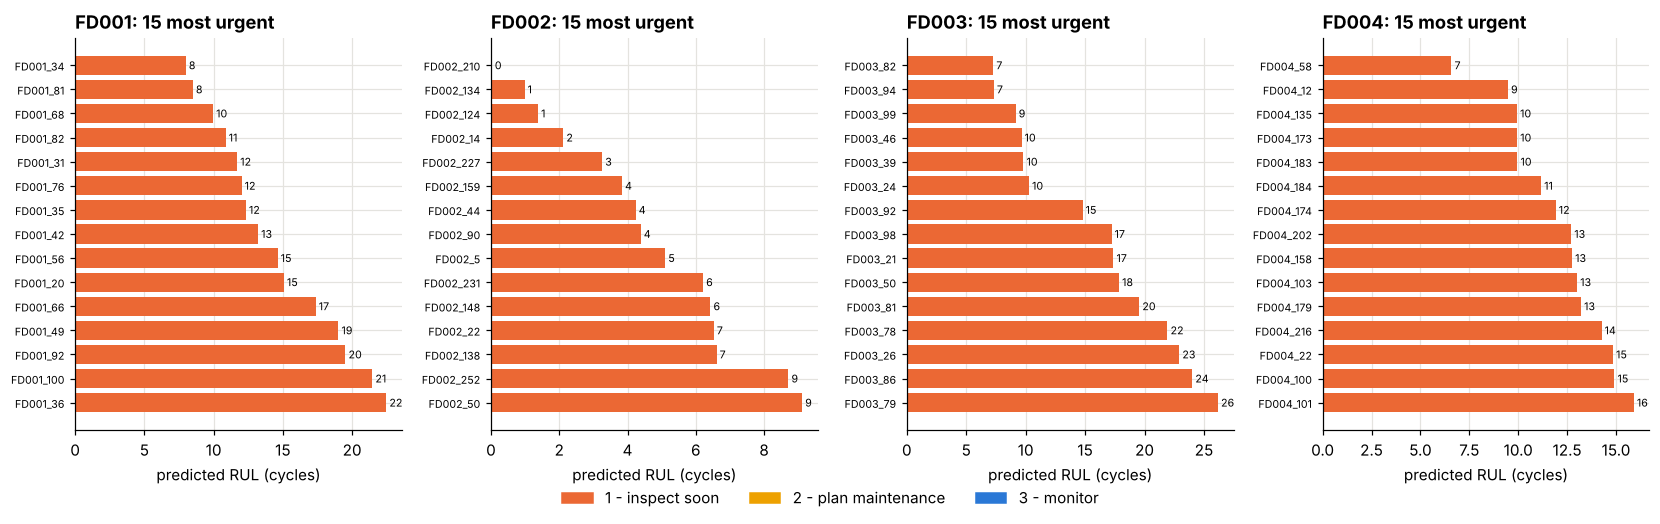

In [ ]:
def priority_band(predicted):
    return np.select([predicted <= 30, predicted <= 60], ["1 - inspect soon", "2 - plan maintenance"], "3 - monitor")


priority_tables = []
for _, best in best_core.iterrows():
    part = main_predictions[(main_predictions["subset"] == best["subset"]) & (main_predictions["model"] == best["model"])
                            & (main_predictions["feature_set"] == best["feature_set"])].copy()
    part = part.sort_values("predicted_RUL").reset_index(drop=True)
    part.insert(0, "rank", np.arange(1, len(part) + 1))
    part["priority"] = priority_band(part["predicted_RUL"])
    priority_tables.append(part)
priority = pd.concat(priority_tables)
priority.to_csv(TABLE_DIR / "maintenance_priority.csv", index=False)
for subset, part in priority.groupby("subset"):
    print(f"{subset} - model: {part['model'].iloc[0]} ({part['feature_set'].iloc[0]})")
    display(part[["rank", "engine_key", "predicted_RUL", "priority", "true_RUL", "error"]].head(10).round(1))

band_colors = {"1 - inspect soon": ORANGE, "2 - plan maintenance": YELLOW, "3 - monitor": BLUE}
fig, axes = plt.subplots(1, len(SUBSETS), figsize=(3.8 * len(SUBSETS), 4.6), squeeze=False)
for i, (subset, part) in enumerate(priority.groupby("subset")):
    top = part.head(15).iloc[::-1]
    bars = axes[0, i].barh(top["engine_key"], top["predicted_RUL"], color=[band_colors[b] for b in top["priority"]])
    axes[0, i].bar_label(bars, fmt="%.0f", fontsize=7, padding=2)   # shows the value even when it is 0
    axes[0, i].set_title(f"{subset}: 15 most urgent")
    axes[0, i].set_xlabel("predicted RUL (cycles)")
    axes[0, i].tick_params(axis="y", labelsize=7)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in band_colors.values()]
fig.legend(handles, band_colors.keys(), loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout()
save_figure(fig, "maintenance_priority.png")

## 11. Save the configuration for the reproducibility appendix

In [ ]:
config = {
    "settings": {"subsets": SUBSETS, "random_state": RANDOM_STATE, "seeds": SEEDS, "history_window": HISTORY_WINDOW,
                 "endpoints_per_engine": N_ENDPOINTS, "outer_folds": OUTER_FOLDS, "inner_folds": INNER_FOLDS,
                 "near_failure_rul": NEAR_FAILURE_RUL, "overestimate_limit": OVERESTIMATE_LIMIT,
                 "n_bootstrap": N_BOOTSTRAP, "rul_cap_extension": RUL_CAP, "n_conditions": N_CONDITIONS,
                 "n_iter": N_ITER, "lstm_trials": LSTM_TRIALS, "lstm_max_epochs": LSTM_MAX_EPOCHS,
                 "lstm_patience": LSTM_PATIENCE, "lstm_batch": LSTM_BATCH, "quick_run": QUICK_RUN},
    "search_spaces": SEARCH_SPACES,
    "lstm_search_space": LSTM_SPACE,
    "outer_fold_engines": outer_fold_lists,
    "nested_cv_best_params": nested_params,
    "final_params": {f"{s}|{m}|{f}": p for (s, m, f), p in final_params.items()},
    "best_core_model_by_nested_cv": best_core.to_dict(orient="records"),
    "versions": versions,
    "hardware": hardware,
    "total_minutes": (time.time() - NOTEBOOK_START) / 60,
}
with open(CONFIG_DIR / "run_config.json", "w") as file:
    json.dump(config, file, indent=2, default=str)
print("Saved tables to", TABLE_DIR)
print("Saved figures to", FIG_DIR)
print("Saved predictions to", PRED_DIR)
print("Saved configuration to", CONFIG_DIR / "run_config.json")
print(f"Total run time: {(time.time() - NOTEBOOK_START) / 60:.1f} minutes")

Saved tables to /tmp/claude-0/-home-user/55e1d562-51e0-5b6d-9458-d82f4f871ad5/scratchpad/repo/AircraftMaintenance/results/tables
Saved figures to /tmp/claude-0/-home-user/55e1d562-51e0-5b6d-9458-d82f4f871ad5/scratchpad/repo/AircraftMaintenance/results/figures
Saved predictions to /tmp/claude-0/-home-user/55e1d562-51e0-5b6d-9458-d82f4f871ad5/scratchpad/repo/AircraftMaintenance/results/predictions
Saved configuration to /tmp/claude-0/-home-user/55e1d562-51e0-5b6d-9458-d82f4f871ad5/scratchpad/repo/AircraftMaintenance/results/configs/run_config.json
Total run time: 167.3 minutes
